## 0. Setup

In [3]:
# Instala MLflow y Optuna para registrar y comparar corridas.
%pip install -q mlflow optuna tensorboard wordcloud


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
# Prepara las librerías, el dispositivo y las semillas.
import re
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.tokenize import word_tokenize

from torch.utils.tensorboard import SummaryWriter
import mlflow
import mlflow.pytorch
import optuna
SEEDS = [3, 9, 27]
#Se dejan multiple semillas para futuras simulaciones y para comprobar.

# Elegir manualmente: 0 → 3, 1 → 9, 2 → 27.
SEED_SELECTOR = 0
SEED = SEEDS[SEED_SELECTOR]

# Mantiene las mismas particiones entre experimentos.
SPLIT_SEED = 42


def set_seed(seed):
    """Reinicia las fuentes de aleatoriedad del entrenamiento."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed(SEED)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif hasattr(torch, "xpu") and torch.xpu.is_available():
    device = torch.device("xpu")
else:
    device = torch.device("cpu")

print("Semillas disponibles:", SEEDS)
print("Semilla de entrenamiento seleccionada:", SEED)
print("Semilla de partición:", SPLIT_SEED)
print("Dispositivo:", device)

C:\Users\franc\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Semillas disponibles: [3, 9, 27]
Semilla de entrenamiento seleccionada: 3
Semilla de partición: 42
Dispositivo: xpu


In [5]:
# Descarga los recursos de NLTK usados al tokenizar y lematizar.
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")
nltk.download("punkt")
nltk.download("punkt_tab")


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\franc\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\franc\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\franc\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\franc\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\franc\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\franc\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

## 1. Datos: 20 Newsgroups

Sacamos encabezados, pies y citas porque pueden revelar la categoría del
documento. Dividimos el train oficial en train (9052 documentos) y dev
(2262). Usamos la semilla 42, conservamos aproximadamente las proporciones
de las clases y agrupamos las copias del mismo texto para que queden en
la misma partición. El test oficial se carga en la sección 9.

In [6]:
# Separa train y dev sin repartir copias del mismo texto entre ambos.
import hashlib

newsgroups_train = fetch_20newsgroups(
    subset="train", remove=("headers", "footers", "quotes"),
)
class_names = newsgroups_train.target_names
NUM_CLASSES = len(class_names)


def document_key(text):
    return " ".join(text.lower().split())


document_keys = [document_key(text) for text in newsgroups_train.data]
groups = [f"text:{key}" if key else f"empty:{i}" for i, key in enumerate(document_keys)]
known_document_keys = {key for key in document_keys if key}
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SPLIT_SEED)
train_indices, dev_indices = next(
    splitter.split(np.arange(len(groups)), newsgroups_train.target, groups)
)
assert set(np.asarray(groups, dtype=object)[train_indices]).isdisjoint(
    np.asarray(groups, dtype=object)[dev_indices]
)
data_digest = hashlib.sha256()
for text in newsgroups_train.data:
    data_digest.update(hashlib.sha256(text.encode("utf-8")).digest())
for indices in (train_indices, dev_indices):
    data_digest.update(np.asarray(indices, dtype="<i8").tobytes())
DATA_SPLIT_ID = data_digest.hexdigest()

train_texts_raw = [newsgroups_train.data[i] for i in train_indices]
dev_texts_raw = [newsgroups_train.data[i] for i in dev_indices]
y_train = newsgroups_train.target[train_indices]
y_dev = newsgroups_train.target[dev_indices]
print(f"Train: {len(y_train)} | Dev: {len(y_dev)}")

Train: 9052 | Dev: 2262



Train: 9052 documentos (80.01% del train oficial)
Media de documentos por clase: 452.60


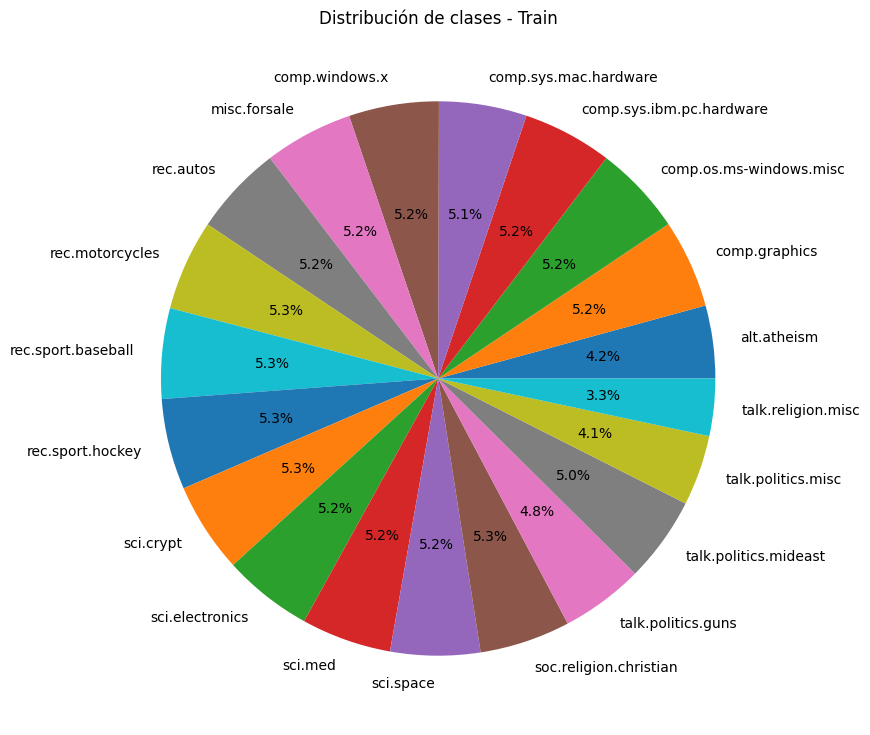


Dev: 2262 documentos (19.99% del train oficial)
Media de documentos por clase: 113.10


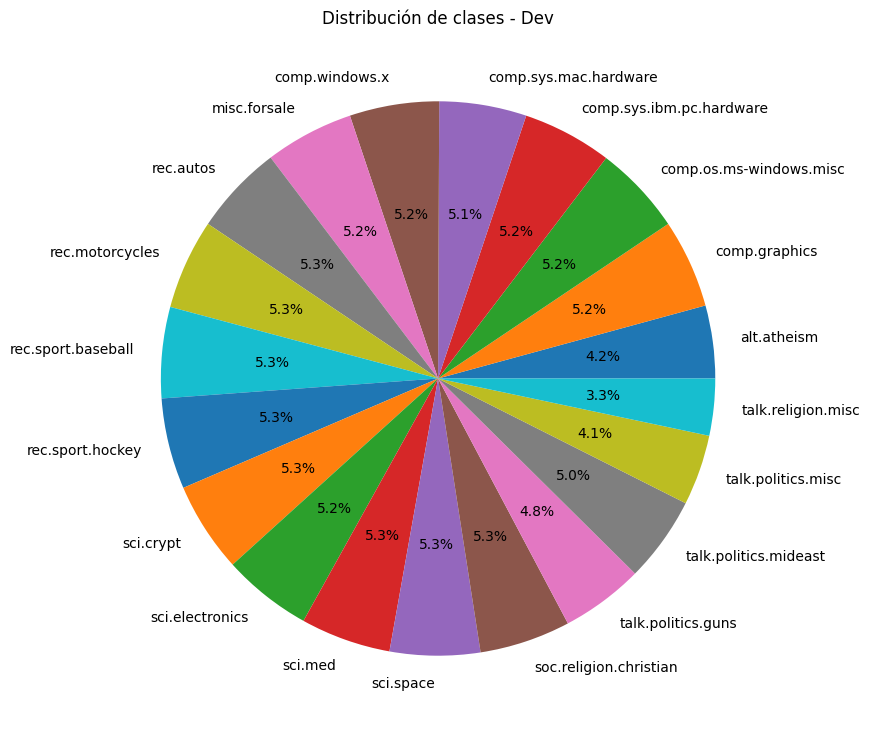

In [7]:
# Muestra la distribución de clases por partición.

total = len(newsgroups_train.data)

for nombre, etiquetas in [
    ("Train", y_train),
    ("Dev", y_dev),
]:
    counts = np.bincount(etiquetas, minlength=NUM_CLASSES)
    distribution = counts / len(etiquetas)

    print(f"\n{nombre}: {len(etiquetas)} documentos "
          f"({100 * len(etiquetas) / total:.2f}% del train oficial)")
    print(f"Media de documentos por clase: {counts.mean():.2f}")

    plt.figure(figsize=(9, 9))
    plt.pie(distribution, labels=class_names, autopct="%1.1f%%")
    plt.title(f"Distribución de clases - {nombre}")
    plt.show()

## 2. Preprocesamiento

Pasamos el texto a minúsculas, conservamos tokens alfabéticos, sacamos
stopwords en inglés y lematizamos. Dejé este preprocesamiento fijo para
concentrar la búsqueda en el modelo y la regularización.

In [8]:
# Limpia y lematiza cada documento antes de vectorizarlo.
STOP_WORDS = set(stopwords.words("english"))
LEMMATIZER = WordNetLemmatizer()


def preprocess_text(text):
    tokens = word_tokenize(text.lower())
    tokens = [t for t in tokens if t.isalpha() and t not in STOP_WORDS]
    tokens = [LEMMATIZER.lemmatize(t) for t in tokens]
    return " ".join(tokens)

Original:      The researchers were studying the running processes and stopping conditions of the engines.
Preprocesado: researcher studying running process stopping condition engine


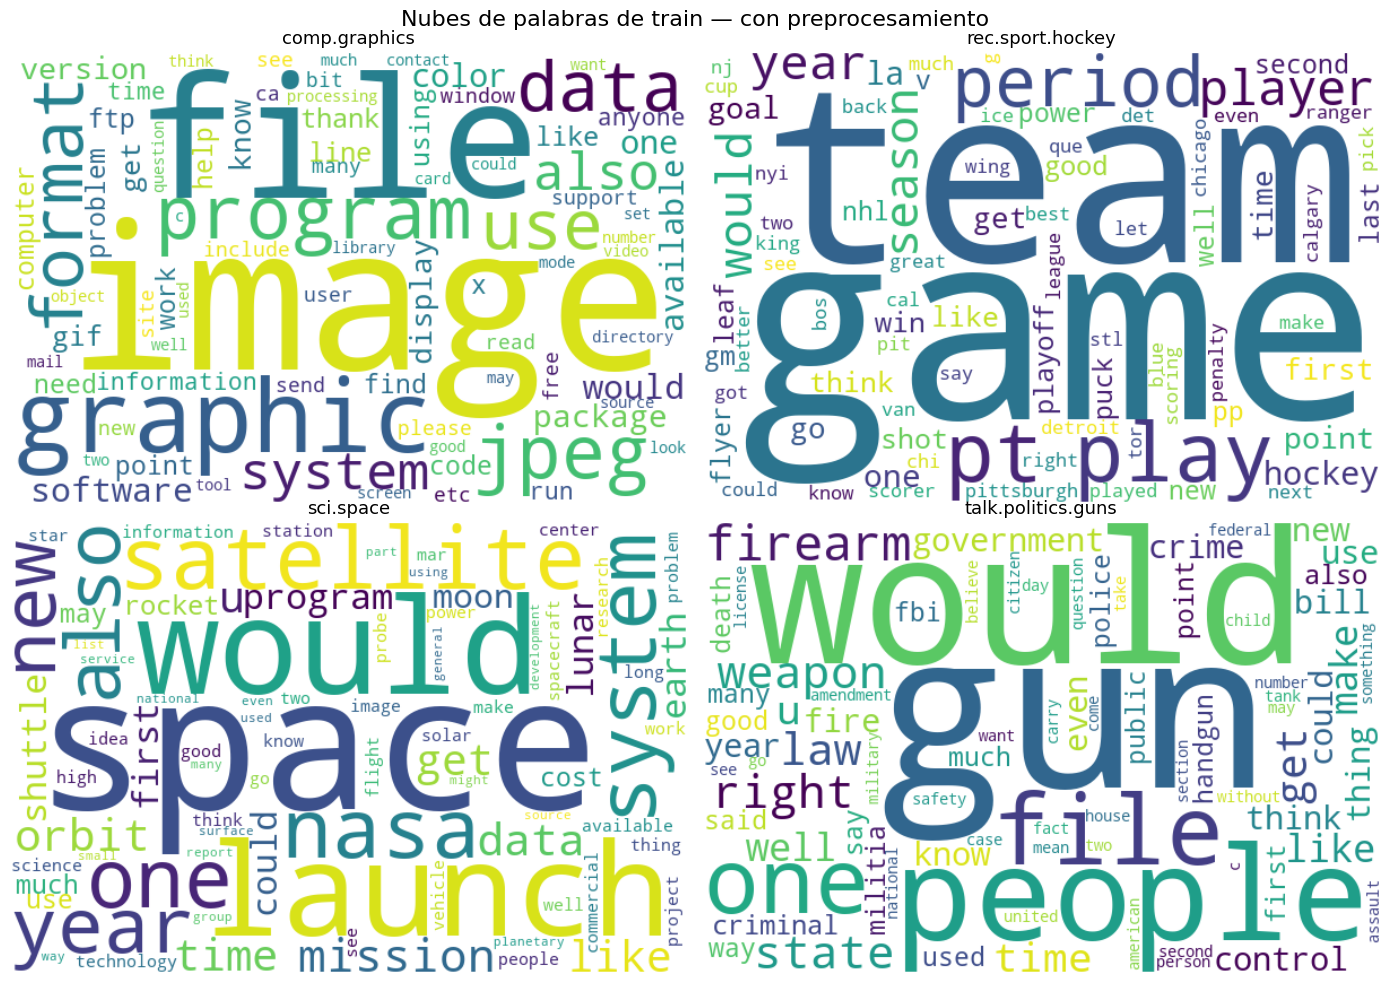

In [9]:
# Muestra un ejemplo de limpieza y las palabras frecuentes de cuatro clases de train.
from wordcloud import WordCloud

ejemplo = (
    "The researchers were studying the running processes "
    "and stopping conditions of the engines."
)

print("Original:     ", ejemplo)
print("Preprocesado:", preprocess_text(ejemplo))

categorias = [
    "comp.graphics",
    "rec.sport.hockey",
    "sci.space",
    "talk.politics.guns",
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for ax, categoria in zip(axes.flat, categorias):
    clase = class_names.index(categoria)
    texto = " ".join(
        preprocess_text(documento)
        for documento, etiqueta in zip(train_texts_raw, y_train)
        if etiqueta == clase
    )

    wc = WordCloud(
        width=600,
        height=400,
        background_color="white",
        colormap="viridis",
        max_words=80,
        stopwords=set(),       # Ya las eliminamos nosotros.
        collocations=False,    # Mostrar palabras individuales.
    ).generate(texto)

    ax.imshow(wc, interpolation="bilinear")
    ax.set_title(categoria, fontsize=13)
    ax.axis("off")

plt.suptitle("Nubes de palabras de train — con preprocesamiento", fontsize=16)
plt.tight_layout()
plt.show()

## 3. Vectorización TF-IDF

Usamos unigramas, hasta 5000 términos, `min_df=1` y norma L2 por documento.
El vocabulario y los IDF se ajustan con train. Transformamos dev y test con
ese mismo vectorizador. La dimensión de entrada es la cantidad de columnas
de TF-IDF.

Mantuve fijos esos valores para comparar los modelos con la misma
representación y reutilizar la vectorización entre trials.

In [10]:
# Ajusta TF-IDF con train y aplica el mismo vocabulario al segundo conjunto.
def vectorize_data(train_texts, other_texts, ngram_range, max_features, min_df):
    """Ajusta TF-IDF con train y transforma el segundo conjunto (dev en la búsqueda).

    Los textos deben estar preprocesados. Los hiperparámetros se eligen
    fuera de este wrapper, en el código de cada experimento.
    """
    my_vectorizer = TfidfVectorizer(
        ngram_range=ngram_range,
        max_features=max_features,
        min_df=min_df
    )
    X_train = my_vectorizer.fit_transform(train_texts)
    X_other =  my_vectorizer.transform(other_texts)
    return X_train, X_other, my_vectorizer

# Conservamos la normalización L2 por documento que aplica TF-IDF.
# No agregamos estandarización z-score.

In [11]:
# Comprueba el vocabulario y la norma L2 con textos cortos.
_sample_train = [
    "the cat sat on the mat",
    "dogs are running in the park",
    "cats and dogs are pets",
]
_sample_test = ["the dog sat on the mat"]

_sample_train = [preprocess_text(t) for t in _sample_train]
_sample_test = [preprocess_text(t) for t in _sample_test]

_Xtr, _Xte, _vec = vectorize_data(
    _sample_train, _sample_test,
    ngram_range=(1, 1), max_features=50, min_df=1,
)

assert _Xtr.shape[1] == _Xte.shape[1]
assert "the" not in _vec.vocabulary_
assert "dog" in _vec.vocabulary_

print("Train preprocesado:", _sample_train)
print("Test preprocesado:", _sample_test)
print("Shape train:", _Xtr.shape, "| Shape test:", _Xte.shape)

print("\nScores del documento de test:")
for word, score in zip(_vec.get_feature_names_out(), _Xte.toarray()[0]):
    print(f"{word:15s} {score:.4f}")

_norma = np.sqrt(_Xte.multiply(_Xte).sum())
assert np.isclose(_norma, 1.0)
print(f"\nNorma L2 del documento de test: {_norma:.4f}")


Train preprocesado: ['cat sat mat', 'dog running park', 'cat dog pet']
Test preprocesado: ['dog sat mat']
Shape train: (3, 7) | Shape test: (1, 7)

Scores del documento de test:
cat             0.0000
dog             0.4736
mat             0.6228
park            0.0000
pet             0.0000
running         0.0000
sat             0.6228

Norma L2 del documento de test: 1.0000


## 4. Modelo MLP

Elegí LeakyReLU con pendiente 0,1 para que las entradas negativas a la
activación sigan aportando gradiente. La mantuve fija para concentrar la
comparación en la regularización y la arquitectura. El baseline tiene una
capa oculta de 256 neuronas. En Optuna probamos de una a tres capas, con
128, 256 o 512 neuronas en cada una.

En cada capa oculta, BatchNorm va antes de LeakyReLU y Dropout después,
cuando están activos. Si hay BatchNorm, la capa lineal anterior va sin
sesgo. La salida lineal entrega 20 logits a la entropía cruzada.

Inicializamos los pesos lineales con Xavier uniforme y los sesgos en cero.
BatchNorm arranca con escala 1 y desplazamiento 0.

In [12]:
# Construye la MLP a partir de los tamaños y la activación elegidos.
class my_MLP_model(nn.Module):
    def __init__(
        self,
        input_dim,
        num_classes,
        hidden_units,
        activation_name,
        batchnorm=False,
        dropout=0.0,
    ):
        super().__init__()

        hidden_units = list(hidden_units)

        if not 1 <= len(hidden_units) <= 3:
            raise ValueError("El modelo debe tener entre 1 y 3 capas ocultas.")

        if any(neurons <= 0 for neurons in hidden_units):
            raise ValueError("La cantidad de neuronas debe ser positiva.")

        if not 0.0 <= dropout < 1.0:
            raise ValueError("dropout debe estar entre 0 inclusive y 1 exclusivo.")

        activations = {
            "sigmoid": nn.Sigmoid,
            "tanh": nn.Tanh,
            "relu": nn.ReLU,
            "elu": nn.ELU,
            "leaky_relu": lambda: nn.LeakyReLU(negative_slope=0.1),
        }

        activation_name = activation_name.lower()

        if activation_name not in activations:
            raise ValueError(f"Activación desconocida: {activation_name}")

        layers = []
        previous_dim = input_dim

        for neurons in hidden_units:
            layers.append(
                nn.Linear(previous_dim, neurons, bias=not batchnorm)
            )

            if batchnorm:
                layers.append(nn.BatchNorm1d(neurons))

            layers.append(activations[activation_name]())

            if dropout > 0:
                layers.append(nn.Dropout(p=dropout))

            previous_dim = neurons

        layers.append(nn.Linear(previous_dim, num_classes))
        self.network = nn.Sequential(*layers)

        # Reemplazamos la inicialización predeterminada de las capas.
        for layer in self.network:
            if isinstance(layer, nn.Linear):
                nn.init.xavier_uniform_(layer.weight)
                if layer.bias is not None:
                    nn.init.zeros_(layer.bias)

            elif isinstance(layer, nn.BatchNorm1d):
                nn.init.ones_(layer.weight)   # Gamma.
                nn.init.zeros_(layer.bias)   # Beta.

    def forward(self, x):
        return self.network(x)

In [13]:
# Comprueba dimensiones, inicialización y gradientes con entradas simuladas.
# fork_rng conserva el estado aleatorio que usará el entrenamiento.
with torch.random.fork_rng(devices=[]):
    configurations_checked = 0

    for widths in [[32], [32, 16], [32, 16, 8]]:
        for activation in ["sigmoid", "tanh", "relu", "elu", "leaky_relu"]:
            for batchnorm, dropout in [
                (False, 0.0),
                (True, 0.0),
                (False, 0.3),
            ]:
                check_model = my_MLP_model(
                    input_dim=50,
                    num_classes=NUM_CLASSES,
                    hidden_units=widths,
                    activation_name=activation,
                    batchnorm=batchnorm,
                    dropout=dropout,
                )

                # Verificamos la pendiente negativa elegida para LeakyReLU.
                for layer in check_model.network:
                    if isinstance(layer, nn.LeakyReLU):
                        assert layer.negative_slope == 0.1
                        assert torch.allclose(
                            layer(torch.tensor([-2.0, 2.0])),
                            torch.tensor([-0.2, 2.0]),
                        )

                # Comprobamos los sesgos antes del entrenamiento.
                for layer in check_model.network:
                    if isinstance(layer, nn.Linear) and layer.bias is not None:
                        assert torch.all(layer.bias == 0)

                inputs = torch.randn(4, 50)
                targets = torch.randint(NUM_CLASSES, (4,))

                check_model.train()
                logits = check_model(inputs)

                assert logits.shape == (4, NUM_CLASSES)
                assert torch.isfinite(logits).all()

                loss = nn.CrossEntropyLoss()(logits, targets)
                loss.backward()

                assert all(
                    p.grad is not None and torch.isfinite(p.grad).all()
                    for p in check_model.parameters()
                )

                # En evaluación no debe haber aleatoriedad de Dropout.
                check_model.eval()
                with torch.no_grad():
                    prediction = check_model(inputs)
                    assert torch.equal(prediction, check_model(inputs))

                configurations_checked += 1

    print(f"Configuraciones verificadas: {configurations_checked}")
    print("Sesgos en cero, dimensiones, gradientes y evaluación: OK")

Configuraciones verificadas: 45
Sesgos en cero, dimensiones, gradientes y evaluación: OK


## 5. Entrenamiento

Pasamos TF-IDF a tensores densos `float32`, el mismo tipo que usan los
pesos. Así ocupamos la mitad de memoria por valor que con `float64`.

Mezclamos train al actualizar los pesos. Al final de cada época medimos
accuracy y entropía cruzada en train y dev con `model.eval()`. Ahí se
desactiva Dropout y BatchNorm usa las estadísticas acumuladas. Si queda un
batch de un solo ejemplo con BatchNorm, se omite solo al actualizar los
pesos. El test se usa en la sección 9.

Usamos Adam, hasta 40 épocas y batches de 64, 128 o 256. Guardamos el mejor
estado según accuracy de dev. También quedan los valores de la pérdida por
batch, la magnitud de los pesos, el LR y los tiempos. Medimos con
`time.perf_counter()` y sincronizamos la GPU al tomar los tiempos.

Probamos early stopping en 7.6 y 7.7. Usamos una paciencia de referencia
de 15 épocas sin mejorar la accuracy de dev. En 8 y 9 entrenamos 40 épocas
y recuperamos el mejor estado de dev.

In [14]:
# Fija los valores de referencia para las próximas corridas.
MAX_EPOCHS = 40  # cambiar manualmente
EARLY_STOPPING_PATIENCE = 15  # fijo; no se optimiza con Optuna
BATCH_SIZES = [64, 128, 256]
ACTIVATION = "leaky_relu"
BASELINE_HIDDEN_UNITS = [256]
BASELINE_BATCH_SIZE = 128
BASELINE_LR = 0.0024524713668806378

### Función de costo J

`classification_cost` envuelve `nn.CrossEntropyLoss`: recibe logits sin
Softmax y etiquetas enteras. Durante el entrenamiento calcula la entropía
cruzada promedio del batch. Durante la evaluación suma las pérdidas y luego
el evaluador divide por el total de ejemplos, para no dar el mismo peso a
batches de tamaños diferentes.

`regularization_cost` calcula las contribuciones L1 y L2. Las sumas incluyen
los pesos de todas las capas lineales, incluida la salida, y excluyen sesgos
y parámetros de BatchNorm. Su magnitud depende de la cantidad de parámetros.

El wrapper `J` reúne los componentes:

$$
J = J_{\mathrm{CE}} + \lambda_1 \sum_j |w_j| + \lambda_2 \sum_j w_j^2.
$$

Devuelve `J_total`, `J_ce`, `J_l1` y `J_l2`. Aplicamos `backward()` sobre
`J_total`, conservando las operaciones de penalización en el grafo de
cálculo. Con ambos coeficientes en cero, `J_total` coincide con `J_ce`.
Dejamos `weight_decay=0` para no duplicar L2.

Las curvas de clasificación (`train_loss` y `val_loss`) registran solamente
entropía cruzada. `train_objective` registra J durante las actualizaciones;
las contribuciones de regularización se conservan por separado. La métrica
principal de selección sigue siendo accuracy de dev.


In [15]:
# Calcula la entropía cruzada y las penalizaciones de J.
def classification_cost(logits, targets, reduction="mean"):
    """Wrapper de entropía cruzada: recibe logits y etiquetas de clase."""
    criterion = nn.CrossEntropyLoss(reduction=reduction)
    return criterion(logits, targets)


def regularization_cost(model, l1_lambda=0.0, l2_lambda=0.0):
    """Devuelve las contribuciones L1 y L2 de los pesos de capas lineales."""
    if l1_lambda < 0 or l2_lambda < 0:
        raise ValueError("Los coeficientes de regularización no pueden ser negativos.")

    reference = next(model.parameters())
    J_l1 = reference.new_zeros(())
    J_l2 = reference.new_zeros(())

    if l1_lambda or l2_lambda:
        for layer in model.modules():
            if isinstance(layer, nn.Linear):
                if l1_lambda:
                    J_l1 = J_l1 + l1_lambda * layer.weight.abs().sum()
                if l2_lambda:
                    J_l2 = J_l2 + l2_lambda * layer.weight.square().sum()

    return J_l1, J_l2


def J(logits, targets, model, l1_lambda=0.0, l2_lambda=0.0):
    """Costo de entrenamiento y sus componentes, conservando sus gradientes."""
    J_ce = classification_cost(logits, targets)
    J_l1, J_l2 = regularization_cost(model, l1_lambda, l2_lambda)
    J_total = J_ce + J_l1 + J_l2
    return J_total, J_ce, J_l1, J_l2


In [16]:
# Prepara los batches, el optimizador y las métricas de evaluación.
import time
from scipy import sparse


def to_tensor_dataset(X, y):
    # Convertimos a float32 antes de densificar para reducir la memoria necesaria.
    if sparse.issparse(X):
        X = X.astype(np.float32).toarray()
    X = torch.as_tensor(np.asarray(X), dtype=torch.float32)
    y = torch.as_tensor(np.asarray(y), dtype=torch.long)
    if X.ndim != 2 or y.ndim != 1 or len(X) != len(y) or len(y) == 0:
        raise ValueError("Se esperan características 2D y etiquetas 1D alineadas y no vacías.")
    return TensorDataset(X, y)


def make_loaders(train_dataset, dev_dataset, batch_size, seed, batchnorm=False):
    if batch_size < 1 or (batchnorm and (batch_size < 2 or len(train_dataset) < 2)):
        raise ValueError("BatchNorm necesita al menos dos ejemplos por batch de entrenamiento.")
    generator = torch.Generator().manual_seed(seed)
    # BatchNorm no puede entrenarse con un último batch de un solo ejemplo.
    drop_last = batchnorm and len(train_dataset) % batch_size == 1
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True,
                              generator=generator, drop_last=drop_last)
    train_eval_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=False,
                                  generator=torch.Generator().manual_seed(seed + 1))
    dev_loader = DataLoader(dev_dataset, batch_size=batch_size, shuffle=False,
                           generator=torch.Generator().manual_seed(seed + 2))
    return train_loader, train_eval_loader, dev_loader


def create_optimizer(model, optimizer_name, lr, **parameters):
    optimizers = {"adam": optim.Adam, "rmsprop": optim.RMSprop, "sgd": optim.SGD}
    name = optimizer_name.lower()
    if name not in optimizers:
        raise ValueError(f"Optimizador desconocido: {optimizer_name}")
    # L2 se agrega explícitamente a la pérdida; evitamos penalizarla dos veces.
    if parameters.get("weight_decay", 0) != 0:
        raise ValueError("Usar weight_decay=0; la regularización L2 se configura en train_mlp_model.")
    if name == "adam" and next(model.parameters()).device.type == "xpu":
        # La actualización agrupada de Adam falla en esta GPU Intel.
        parameters.setdefault("foreach", False)
    return optimizers[name](model.parameters(), lr=lr, **parameters)


@torch.no_grad()
def evaluate_model(model, loader):
    model.eval()
    model_device = next(model.parameters()).device
    loss_sum, correct, count = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(model_device), yb.to(model_device)
        logits = model(xb)
        loss_sum += classification_cost(logits, yb, reduction="sum").item()
        correct += (logits.argmax(dim=1) == yb).sum().item()
        count += len(yb)
    if count == 0:
        raise ValueError("El conjunto de evaluación está vacío.")
    return loss_sum / count, correct / count


@torch.no_grad()
def weight_statistics(model):
    statistics = {}
    for name, layer in model.named_modules():
        if isinstance(layer, nn.Linear):
            weights = layer.weight.abs()
            statistics[name] = {"mean_abs": weights.mean().item(),
                                "max_abs": weights.max().item()}
    return statistics




In [17]:
# Entrena por batches y selecciona el mejor estado según dev.
def train_mlp_model(
    model, train_loader, train_eval_loader, dev_loader, optimizer, epochs=MAX_EPOCHS,
    l1_lambda=0.0, l2_lambda=0.0, writer=None, log_mlflow=False,
    scheduler=None, monitor="val_acc", patience=EARLY_STOPPING_PATIENCE,
    restore_best=True, run_name="mlp", verbose=True,
    batch_callback=None, epoch_callback=None, last_epoch_callback=None,
):
    if epochs < 1 or min(l1_lambda, l2_lambda) < 0:
        raise ValueError("Las épocas deben ser positivas y las penalizaciones no negativas.")
    if monitor not in ("val_acc", "val_loss"):
        raise ValueError("monitor debe ser val_acc o val_loss.")
    if patience is not None and patience < 1:
        raise ValueError("patience debe ser positivo o None.")
    if any(group.get("weight_decay", 0) != 0 for group in optimizer.param_groups):
        raise ValueError("Usar weight_decay=0 para controlar L2 explícitamente.")
    if isinstance(scheduler, optim.lr_scheduler.ReduceLROnPlateau):
        expected_mode = "max" if monitor == "val_acc" else "min"
        if scheduler.mode != expected_mode:
            raise ValueError("El modo del scheduler no coincide con monitor.")
    if log_mlflow and mlflow.active_run() is None:
        raise ValueError("Abrir un run de MLflow antes de registrar el entrenamiento.")

    # Mover el modelo antes de construir el optimizador, especialmente al usar GPU.
    model_device = next(model.parameters()).device
    linear_weights = [layer.weight for layer in model.modules()
                      if isinstance(layer, nn.Linear)]
    if not linear_weights or len(train_loader) == 0:
        raise ValueError("Se requieren capas lineales y batches de entrenamiento.")

    keys = ["train_loss", "train_acc", "val_loss", "val_acc", "gap_acc",
            "train_batch_loss", "train_batch_acc", "train_objective",
            "train_seconds", "eval_seconds", "epoch_seconds", "lr",
            "l1_penalty", "l2_penalty"]
    history = {key: [] for key in keys}
    history["max_epochs"] = epochs
    history["patience"] = patience
    history["weights"] = []
    history["initial_weights"] = weight_statistics(model)
    best_value, best_state, best_epoch, without_improvement = None, None, 0, 0
    if writer is not None:
        for name, layer in model.named_modules():
            if isinstance(layer, nn.Linear):
                writer.add_histogram(f"weights_abs/{name}", layer.weight.detach().abs().cpu(), 0)

    def synchronize():
        if model_device.type == "cuda":
            torch.cuda.synchronize(model_device)
        elif model_device.type == "xpu":
            torch.xpu.synchronize(model_device)

    synchronize()
    total_start = time.perf_counter()
    for epoch in range(epochs):
        model.train()
        lr = optimizer.param_groups[0]["lr"]
        synchronize()
        epoch_start = time.perf_counter()
        loss_sum, objective_sum, correct, count = 0.0, 0.0, 0, 0

        for batch_number, (xb, yb) in enumerate(train_loader, start=1):
            xb, yb = xb.to(model_device), yb.to(model_device)
            optimizer.zero_grad(set_to_none=True)
            logits = model(xb)
            J_total, J_ce, _, _ = J(
                logits, yb, model, l1_lambda=l1_lambda, l2_lambda=l2_lambda,
            )
            if not torch.isfinite(J_total):
                raise FloatingPointError("Costo no finito; revisar learning rate y regularización.")
            J_total.backward()
            batch_lr = optimizer.param_groups[0]["lr"]
            optimizer.step()
            if isinstance(scheduler, optim.lr_scheduler.CyclicLR):
                scheduler.step()
            n = len(yb)
            loss_sum += J_ce.item() * n
            objective_sum += J_total.item() * n
            correct += (logits.argmax(dim=1) == yb).sum().item()
            count += n
            if batch_callback is not None:
                batch_callback(epoch + 1, batch_number, {
                    "examples": n, "J_ce": J_ce.item(), "J_total": J_total.item(),
                    "accuracy": (logits.argmax(dim=1) == yb).float().mean().item(),
                    "lr": batch_lr,
                })

        synchronize()
        train_seconds = time.perf_counter() - epoch_start
        eval_start = time.perf_counter()
        train_loss, train_acc = evaluate_model(model, train_eval_loader)
        val_loss, val_acc = evaluate_model(model, dev_loader)
        if not np.isfinite([train_loss, val_loss]).all():
            raise FloatingPointError("Pérdida de evaluación no finita.")
        synchronize()
        eval_seconds = time.perf_counter() - eval_start
        with torch.no_grad():
            J_l1, J_l2 = regularization_cost(model, l1_lambda, l2_lambda)
            l1_penalty, l2_penalty = J_l1.item(), J_l2.item()
        statistics = weight_statistics(model)
        synchronize()
        metrics = dict(train_loss=train_loss, train_acc=train_acc, val_loss=val_loss,
                       val_acc=val_acc, gap_acc=train_acc - val_acc,
                       train_batch_loss=loss_sum / count, train_batch_acc=correct / count,
                       train_objective=objective_sum / count, train_seconds=train_seconds,
                       eval_seconds=eval_seconds, epoch_seconds=time.perf_counter() - epoch_start,
                       lr=lr, l1_penalty=l1_penalty, l2_penalty=l2_penalty)
        for key, value in metrics.items():
            history[key].append(value)
        history["weights"].append(statistics)

        # Guardamos el estado completo porque BatchNorm también usa estadísticas acumuladas.
        value = metrics[monitor]
        improved = best_value is None or (value > best_value if monitor == "val_acc" else value < best_value)
        if improved:
            best_value, best_epoch, without_improvement = value, epoch + 1, 0
            if restore_best:
                best_state = {name: tensor.detach().cpu().clone()
                              for name, tensor in model.state_dict().items()}
        else:
            without_improvement += 1

        if epoch_callback is not None:
            epoch_callback(model, history)

        log_metrics = dict(metrics)
        for name, values in statistics.items():
            for statistic, number in values.items():
                log_metrics[f"weights/{name}/{statistic}"] = number
        if writer is not None:
            for key, number in log_metrics.items():
                writer.add_scalar(key, number, epoch + 1)
            if epoch == 0 or (epoch + 1) % 5 == 0 or epoch + 1 == epochs:
                for name, layer in model.named_modules():
                    if isinstance(layer, nn.Linear):
                        writer.add_histogram(f"weights_abs/{name}", layer.weight.detach().abs().cpu(), epoch + 1)
        if log_mlflow:
            mlflow.log_metrics(log_metrics, step=epoch + 1)
        if verbose:
            print(f"[{run_name}] {epoch + 1}/{epochs} | "
                  f"train loss={train_loss:.4f} acc={train_acc:.4f} | "
                  f"dev loss={val_loss:.4f} acc={val_acc:.4f} | "
                  f"lr={lr:.2g} | entrenamiento={train_seconds:.2f}s")
        if scheduler is not None and not isinstance(scheduler, optim.lr_scheduler.CyclicLR):
            if isinstance(scheduler, optim.lr_scheduler.ReduceLROnPlateau):
                scheduler.step(value)
            else:
                scheduler.step()
        if patience is not None and without_improvement >= patience:
            if verbose:
                print(f"Early stopping: {patience} épocas sin mejora de {monitor}. "
                      f"Mejor época: {best_epoch}.")
            break

    synchronize()
    history["total_seconds"] = time.perf_counter() - total_start
    history["best_epoch"] = best_epoch
    history["best_value"] = best_value
    history["monitor"] = monitor
    history["epochs_completed"] = len(history["val_loss"])
    history["stopped_early"] = history["epochs_completed"] < epochs
    history["stop_reason"] = "early_stopping" if history["stopped_early"] else "max_epochs"
    if last_epoch_callback is not None:
        last_epoch_callback(model)
    if restore_best:
        model.load_state_dict(best_state)
    model.eval()
    history["returned_epoch"] = best_epoch if restore_best else history["epochs_completed"]
    history["train_seconds_to_best"] = sum(history["train_seconds"][:best_epoch])
    history["returned_weights"] = weight_statistics(model)
    if writer is not None:
        writer.flush()
    if log_mlflow:
        mlflow.log_metrics({"best_epoch": best_epoch, "best_value": best_value,
                            "total_seconds": history["total_seconds"]})
    return history

In [18]:
# Grafica la pérdida y la accuracy a partir del historial.
def plot_training_history(history):
    epochs = np.arange(1, history["epochs_completed"] + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(epochs, history["train_loss"], label="Train (eval)")
    axes[0].plot(epochs, history["val_loss"], label="Dev")
    axes[0].plot(epochs, history["train_batch_loss"], label="Train durante actualizaciones", alpha=0.5)
    axes[0].set_title("Pérdida de clasificación, sin penalización")
    axes[1].plot(epochs, history["train_acc"], label="Train (eval)")
    axes[1].plot(epochs, history["val_acc"], label="Dev")
    axes[1].plot(epochs, history["train_batch_acc"], label="Train durante actualizaciones", alpha=0.5)
    axes[1].set_title("Accuracy")
    for ax in axes.flat:
        ax.set_xlabel("Época")
        ax.legend()
        ax.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()


In [19]:
# Prueba el ciclo de entrenamiento con datos simulados.
with torch.random.fork_rng(devices=[]):
    torch.manual_seed(3)
    _x = torch.randn(24, 6)
    _y = (_x[:, 0] > 0).long()
    _train = to_tensor_dataset(_x[:17], _y[:17])
    _dev = to_tensor_dataset(_x[17:], _y[17:])
    _loaders = make_loaders(_train, _dev, batch_size=8, seed=3, batchnorm=True)

    _check_model = my_MLP_model(
        input_dim=6, num_classes=2, hidden_units=[8],
        activation_name="relu", batchnorm=True,
    )
    _optimizer = create_optimizer(_check_model, "Adam", lr=0.01)
    _history = train_mlp_model(
        _check_model, *_loaders, _optimizer, epochs=2,
        l1_lambda=1e-5, l2_lambda=1e-4, verbose=False,
    )

    assert _history["epochs_completed"] == 2
    assert sum(len(yb) for _, yb in _loaders[1]) == 17
    _loss, _accuracy = evaluate_model(_check_model, _loaders[2])
    _best_index = _history["returned_epoch"] - 1
    assert np.isclose(_loss, _history["val_loss"][_best_index])
    assert np.isclose(_accuracy, _history["val_acc"][_best_index])
    assert np.isfinite(_history["train_objective"]).all()
    print("Entrenamiento, L1/L2, BatchNorm y recuperación del modelo: OK")
    print("Sanity check con datos simulados; no se utilizó el test de 20NG.")


Entrenamiento, L1/L2, BatchNorm y recuperación del modelo: OK
Sanity check con datos simulados; no se utilizó el test de 20NG.


## 6. Modelo sin regularización: my_baseline

Del MLP del TP2 tomamos la capa oculta de 256 neuronas y el LR de Adam.
En este TP usamos LeakyReLU y bajamos el batch a 128 para observar la
variación de la pérdida entre batches. Entrenamos con LR fijo y guardamos
los pesos iniciales, los de la mejor época en dev y los de la última.

In [20]:
# my_baseline: configura la corrida y prepara train y dev.
from datetime import datetime
from pathlib import Path
import csv
import hashlib
import json
import platform
import os
import joblib
import nltk
import sklearn

my_baseline_config = {
    "experiment": "my_baseline", "seed": SEED, "split_seed": SPLIT_SEED, "split_id": DATA_SPLIT_ID,
    "hidden_units": BASELINE_HIDDEN_UNITS, "activation": ACTIVATION, "initialization": "xavier_uniform",
    "optimizer": "Adam", "lr": BASELINE_LR,
    "beta1": 0.9, "beta2": 0.999, "batch_size": BASELINE_BATCH_SIZE,
    "max_epochs": MAX_EPOCHS, "patience": None,
    "remove_stopwords": True, "text_normalization": "lemmatize",
    "ngram_range": [1, 1], "max_features": 5000, "min_df": 1,
    "tfidf_norm": "l2", "z_score": False, "dtype": "float32",
    "l1_lambda": 0.0, "l2_lambda": 0.0, "dropout": 0.0,
    "batchnorm": False, "weight_decay": 0.0, "scheduler": None,
}

my_project_dir = Path.cwd()
if not (my_project_dir / "TP_Regularización.ipynb").exists():
    my_project_dir = my_project_dir / "TP RN Regularización Bonacina"
if not (my_project_dir / "TP_Regularización.ipynb").exists():
    raise FileNotFoundError("No se encontró el notebook del TP en el directorio de trabajo.")

my_run_label = datetime.now().strftime("%Y%m%d_%H%M%S_%f")
my_run_dir = my_project_dir / ".experimentos" / "my_baseline" / my_run_label
my_run_dir.mkdir(parents=True, exist_ok=False)
torch.set_num_threads(min(4, os.cpu_count() or 1))
my_preparation_start = time.perf_counter()
my_pipeline_start = my_preparation_start

# Se conserva el código de las funciones utilizadas, sin sus salidas.
my_source_notebook = json.loads((my_project_dir / "TP_Regularización.ipynb").read_text(encoding="utf-8"))
my_source_code = "\n\n".join(
    "".join(cell.get("source", [])) for cell in my_source_notebook["cells"]
    if cell["cell_type"] == "code" and not "".join(cell.get("source", [])).startswith(("%", "!"))
)
(my_run_dir / "source_snapshot.py").write_text(my_source_code, encoding="utf-8")
my_baseline_config["source_sha256"] = hashlib.sha256(my_source_code.encode()).hexdigest()
my_baseline_config["device"] = str(device)
my_baseline_config["torch_version"] = str(torch.__version__)
my_baseline_config["sklearn_version"] = sklearn.__version__
my_baseline_config["python_version"] = platform.python_version()
my_baseline_config["cpu_threads"] = torch.get_num_threads()

print("Preparando train y dev; el test queda reservado.", flush=True)
# Ajustamos el vectorizador solo con train para mantener dev fuera del ajuste.
my_text_train = [preprocess_text(text) for text in train_texts_raw]
my_text_dev = [preprocess_text(text) for text in dev_texts_raw]
my_X_train, my_X_dev, my_vectorizer = vectorize_data(
    my_text_train, my_text_dev, ngram_range=(1, 1), max_features=5000, min_df=1,
)
my_train_dataset = to_tensor_dataset(my_X_train, y_train)
my_dev_dataset = to_tensor_dataset(my_X_dev, y_dev)
my_train_loader, my_train_eval_loader, my_dev_loader = make_loaders(
    my_train_dataset, my_dev_dataset, batch_size=BASELINE_BATCH_SIZE, seed=SEED,
)
np.savez_compressed(my_run_dir / "split_indices.npz", train=train_indices, dev=dev_indices)
joblib.dump(my_vectorizer, my_run_dir / "vectorizer.joblib")
# Contamos textos vacíos y filas que quedaron sin términos del vocabulario.
my_quality = {}
for name, texts, matrix in [("train", my_text_train, my_X_train), ("dev", my_text_dev, my_X_dev)]:
    lengths = np.array([len(text.split()) for text in texts])
    my_quality[name] = {
        "documents": len(texts), "empty_texts": int((lengths == 0).sum()),
        "zero_vectors": int((matrix.getnnz(axis=1) == 0).sum()),
        "median_words": float(np.median(lengths)), "max_words": int(lengths.max()),
    }
my_baseline_config["input_dim"] = my_X_train.shape[1]
my_baseline_config["num_classes"] = NUM_CLASSES
my_baseline_config["train_documents"] = len(y_train)
my_baseline_config["dev_documents"] = len(y_dev)
my_quality["majority_class"] = int(np.bincount(y_train).argmax())
my_quality["majority_dev_accuracy"] = float(np.mean(y_dev == my_quality["majority_class"]))

set_seed(SEED)
my_model = my_MLP_model(
    input_dim=my_X_train.shape[1], num_classes=NUM_CLASSES,
    hidden_units=BASELINE_HIDDEN_UNITS, activation_name=ACTIVATION,
).to(device)
my_optimizer = create_optimizer(
    my_model, "Adam", lr=my_baseline_config["lr"], betas=(0.9, 0.999), weight_decay=0,
)
my_initial_weights = {name: layer.weight.detach().cpu().clone()
                      for name, layer in my_model.named_modules() if isinstance(layer, nn.Linear)}
torch.save(my_initial_weights, my_run_dir / "initial_weights.pt")
my_baseline_config["parameter_count"] = sum(p.numel() for p in my_model.parameters())
my_baseline_config["preparation_seconds"] = time.perf_counter() - my_preparation_start
(my_run_dir / "config.json").write_text(json.dumps(my_baseline_config, indent=2), encoding="utf-8")
(my_run_dir / "data_quality.json").write_text(json.dumps(my_quality, indent=2), encoding="utf-8")
print(json.dumps(my_baseline_config, indent=2), flush=True)

Preparando train y dev; el test queda reservado.
{
  "experiment": "my_baseline",
  "seed": 3,
  "split_seed": 42,
  "split_id": "beab1f165980d89e7622eb65778b564b2bca78341859fa84639444244c4edc07",
  "hidden_units": [
    256
  ],
  "activation": "leaky_relu",
  "initialization": "xavier_uniform",
  "optimizer": "Adam",
  "lr": 0.0024524713668806378,
  "beta1": 0.9,
  "beta2": 0.999,
  "batch_size": 128,
  "max_epochs": 40,
  "patience": null,
  "remove_stopwords": true,
  "text_normalization": "lemmatize",
  "ngram_range": [
    1,
    1
  ],
  "max_features": 5000,
  "min_df": 1,
  "tfidf_norm": "l2",
  "z_score": false,
  "dtype": "float32",
  "l1_lambda": 0.0,
  "l2_lambda": 0.0,
  "dropout": 0.0,
  "batchnorm": false,
  "weight_decay": 0.0,
  "scheduler": null,
  "source_sha256": "ac08f0646f21a8183901bd1e74fe024eb03305adb99c689cf36284029ed83ae6",
  "device": "xpu",
  "torch_version": "2.14.1+xpu",
  "sklearn_version": "1.9.1",
  "python_version": "3.14.5",
  "cpu_threads": 4,
  "in

In [21]:
# my_baseline: entrena y guarda métricas y estados del modelo.
my_tracking_uri = "sqlite:///" + (my_project_dir / ".experimentos" / "mlflow.db").as_posix()
mlflow.set_tracking_uri(my_tracking_uri)
my_client = mlflow.tracking.MlflowClient()
my_experiment = my_client.get_experiment_by_name("my_baseline")
if my_experiment is None:
    my_experiment_id = my_client.create_experiment(
        "my_baseline", artifact_location=(my_project_dir / ".experimentos" / "mlflow_artifacts").as_uri(),
    )
else:
    my_experiment_id = my_experiment.experiment_id
my_tb_dir = my_project_dir / ".experimentos" / "tensorboard" / "my_baseline" / my_run_label
my_writer = SummaryWriter(log_dir=str(my_tb_dir))
my_baseline_config["tensorboard_dir"] = str(my_tb_dir)

my_batch_file = (my_run_dir / "batches.csv").open("w", newline="", encoding="utf-8")
my_batch_fields = ["step", "epoch", "batch", "examples", "J_ce", "J_total", "accuracy", "lr"]
my_batch_csv = csv.DictWriter(my_batch_file, fieldnames=my_batch_fields)
my_batch_csv.writeheader()
my_step = 0

# El promedio por época esconde cuánto cambian las métricas entre batches.
def my_record_batch(epoch, batch, values):
    global my_step
    my_step += 1
    my_batch_csv.writerow({"step": my_step, "epoch": epoch, "batch": batch, **values})
    my_writer.add_scalar("batches/J_ce", values["J_ce"], my_step)
    my_writer.add_scalar("batches/accuracy", values["accuracy"], my_step)

def my_record_epoch(model, history):
    epoch = len(history["val_acc"])
    my_batch_file.flush()
    progress = {"epoch": epoch, "max_epochs": my_baseline_config["max_epochs"],
                "train_acc": history["train_acc"][-1], "val_acc": history["val_acc"][-1],
                "train_loss": history["train_loss"][-1], "val_loss": history["val_loss"][-1],
                "train_seconds": history["train_seconds"][-1]}
    (my_run_dir / "progress.json").write_text(json.dumps(progress), encoding="utf-8")
    (my_run_dir / "history_partial.json").write_text(json.dumps(history), encoding="utf-8")
    # Guardamos la última época antes de que el entrenador recupere la mejor.
    if epoch == my_baseline_config["max_epochs"]:
        torch.save({"config": my_baseline_config, "epoch": epoch,
                    "state_dict": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}},
                   my_run_dir / "model_last.pt")

try:
    with mlflow.start_run(experiment_id=my_experiment_id, run_name="my_baseline") as my_run:
        my_baseline_config["mlflow_run_id"] = my_run.info.run_id
        mlflow.log_params({k: json.dumps(v) if isinstance(v, (list, dict)) else str(v)
                           for k, v in my_baseline_config.items()})
        my_baseline_history = train_mlp_model(
            my_model, my_train_loader, my_train_eval_loader, my_dev_loader,
            my_optimizer, epochs=my_baseline_config["max_epochs"],
            l1_lambda=0.0, l2_lambda=0.0, writer=my_writer, log_mlflow=True,
            scheduler=None, patience=None, restore_best=True,
            monitor="val_acc", run_name="my_baseline",
            batch_callback=my_record_batch, epoch_callback=my_record_epoch,
        )
        torch.save({"config": my_baseline_config, "epoch": my_baseline_history["best_epoch"],
                    "state_dict": {k: v.detach().cpu().clone() for k, v in my_model.state_dict().items()}},
                   my_run_dir / "model_best.pt")
        my_baseline_history["pipeline_seconds_before_export"] = time.perf_counter() - my_pipeline_start
        (my_run_dir / "history.json").write_text(json.dumps(my_baseline_history, indent=2), encoding="utf-8")
        (my_run_dir / "config.json").write_text(json.dumps(my_baseline_config, indent=2), encoding="utf-8")
        my_epoch_rows = []
        for epoch in range(my_baseline_history["epochs_completed"]):
            row = {"epoch": epoch + 1}
            row.update({k: v[epoch] for k, v in my_baseline_history.items()
                        if isinstance(v, list) and len(v) == my_baseline_history["epochs_completed"]
                        and k != "weights"})
            for name, statistics in my_baseline_history["weights"][epoch].items():
                row.update({f"{name}_{stat}": value for stat, value in statistics.items()})
            my_epoch_rows.append(row)
        with (my_run_dir / "epochs.csv").open("w", newline="", encoding="utf-8") as stream:
            table_writer = csv.DictWriter(stream, fieldnames=list(my_epoch_rows[0]))
            table_writer.writeheader(); table_writer.writerows(my_epoch_rows)
        for filename in ["config.json", "data_quality.json", "history.json", "epochs.csv",
                         "batches.csv", "model_best.pt", "model_last.pt", "vectorizer.joblib",
                         "initial_weights.pt", "split_indices.npz", "source_snapshot.py"]:
            if filename == "batches.csv":
                my_batch_file.flush()
            mlflow.log_artifact(str(my_run_dir / filename), artifact_path="my_baseline")
finally:
    my_batch_file.close()
    my_writer.close()

my_manifest = {"run_dir": str(my_run_dir), "config": my_baseline_config,
               "epochs_completed": my_baseline_history["epochs_completed"]}
(my_run_dir.parent / "latest.json").write_text(json.dumps(my_manifest, indent=2), encoding="utf-8")
print("Corrida guardada:", my_run_dir, flush=True)
print("Épocas realizadas:", my_baseline_history["epochs_completed"], flush=True)
print("Tiempo de preparación (s):", round(my_baseline_config["preparation_seconds"], 2), flush=True)
print("Tiempo de entrenamiento y evaluación instrumentados (s):",
      round(my_baseline_history["total_seconds"], 2), flush=True)


[my_baseline] 1/40 | train loss=1.0148 acc=0.8078 | dev loss=1.2986 acc=0.6932 | lr=0.0025 | entrenamiento=0.92s
[my_baseline] 2/40 | train loss=0.4876 acc=0.9012 | dev loss=1.0168 acc=0.6967 | lr=0.0025 | entrenamiento=0.35s
[my_baseline] 3/40 | train loss=0.2881 acc=0.9443 | dev loss=0.9915 acc=0.7016 | lr=0.0025 | entrenamiento=0.36s
[my_baseline] 4/40 | train loss=0.1954 acc=0.9630 | dev loss=1.0127 acc=0.6954 | lr=0.0025 | entrenamiento=0.33s
[my_baseline] 5/40 | train loss=0.1525 acc=0.9675 | dev loss=1.0559 acc=0.6857 | lr=0.0025 | entrenamiento=0.27s
[my_baseline] 6/40 | train loss=0.1303 acc=0.9695 | dev loss=1.0879 acc=0.6883 | lr=0.0025 | entrenamiento=0.28s
[my_baseline] 7/40 | train loss=0.1185 acc=0.9696 | dev loss=1.1255 acc=0.6874 | lr=0.0025 | entrenamiento=0.34s
[my_baseline] 8/40 | train loss=0.1114 acc=0.9703 | dev loss=1.1591 acc=0.6848 | lr=0.0025 | entrenamiento=0.32s
[my_baseline] 9/40 | train loss=0.1069 acc=0.9705 | dev loss=1.1893 acc=0.6813 | lr=0.0025 | ent

In [22]:
# my_baseline: compara la mejor época con la última y resume los tiempos.

import json
import pandas as pd

my_best_epoch = my_baseline_history["best_epoch"]
my_last_epoch = my_baseline_history["epochs_completed"]
my_metric_keys = ["train_loss", "val_loss", "train_acc", "val_acc", "gap_acc"]

my_rows = []
for label, epoch in [
    ("Mejor accuracy de dev", my_best_epoch),
    ("Última época", my_last_epoch),
]:
    i = epoch - 1
    row = {"estado": label, "epoch": epoch}
    row.update({key: my_baseline_history[key][i] for key in my_metric_keys})
    my_rows.append(row)

my_summary_table = pd.DataFrame(my_rows)
display(my_summary_table.round(5))

# Volvemos a medir en dev para comprobar que se recuperaron los mejores pesos.
my_best_loss, my_best_acc = evaluate_model(my_model, my_dev_loader)
best_index = my_best_epoch - 1
assert np.isclose(my_best_loss, my_baseline_history["val_loss"][best_index])
assert np.isclose(my_best_acc, my_baseline_history["val_acc"][best_index])

my_training_seconds = sum(my_baseline_history["train_seconds"])
my_timing_summary = {
    "preparation_seconds": my_baseline_config["preparation_seconds"],
    "training_seconds": my_training_seconds,
    "evaluation_seconds": sum(my_baseline_history["eval_seconds"]),
    "trainer_total_seconds": my_baseline_history["total_seconds"],
    "train_seconds_to_best": my_baseline_history["train_seconds_to_best"],
    "mean_train_seconds_per_epoch": my_training_seconds / my_last_epoch,
}
display(pd.DataFrame([my_timing_summary]).round(3))

(my_run_dir / "summary.json").write_text(
    json.dumps({"states": my_rows, "timings": my_timing_summary}, indent=2),
    encoding="utf-8",
)

,estado,epoch,train_loss,val_loss,train_acc,val_acc,gap_acc
0,Mejor accuracy de dev,3,0.28809,0.99152,0.94432,0.70159,0.24273
1,Última época,40,0.09280,1.57199,0.97072,0.66799,0.30273


,preparation_seconds,training_seconds,evaluation_seconds,trainer_total_seconds,train_seconds_to_best,mean_train_seconds_per_epoch
0,13.309,12.189,4.65,17.822,1.628,0.305


856

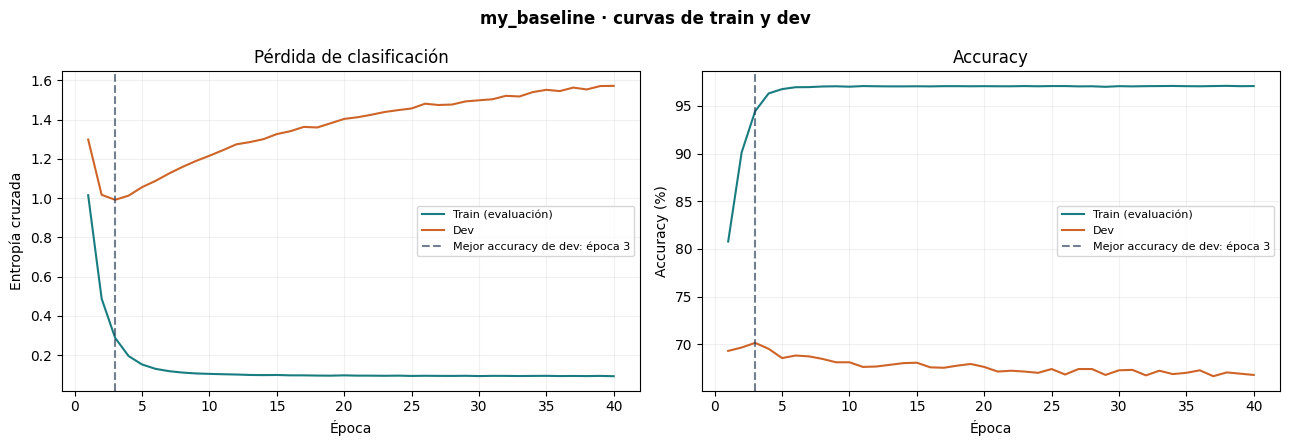

In [23]:
# my_baseline: muestra pérdida y accuracy de train y dev para ubicar el sobreajuste.
my_epochs = np.arange(1, my_baseline_history["epochs_completed"] + 1)
my_best_epoch = my_baseline_history["best_epoch"]

# Curvas de clasificación: ambas particiones se evalúan con pesos de fin de época.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(my_epochs, my_baseline_history["train_loss"], label="Train (evaluación)", color="#197c80")
axes[0].plot(my_epochs, my_baseline_history["val_loss"], label="Dev", color="#ce6427")
axes[0].set_ylabel("Entropía cruzada")
axes[0].set_title("Pérdida de clasificación")
axes[1].plot(my_epochs, np.array(my_baseline_history["train_acc"]) * 100,
             label="Train (evaluación)", color="#197c80")
axes[1].plot(my_epochs, np.array(my_baseline_history["val_acc"]) * 100,
             label="Dev", color="#ce6427")
axes[1].set_ylabel("Accuracy (%)")
axes[1].set_title("Accuracy")
for ax in axes:
    ax.axvline(my_best_epoch, color="#263b56", linestyle="--", alpha=.65,
               label=f"Mejor accuracy de dev: época {my_best_epoch}")
    ax.set_xlabel("Época")
    ax.grid(alpha=.18)
    ax.legend(fontsize=8)
fig.suptitle("my_baseline · curvas de train y dev", fontweight="bold")
plt.tight_layout()
plt.show()



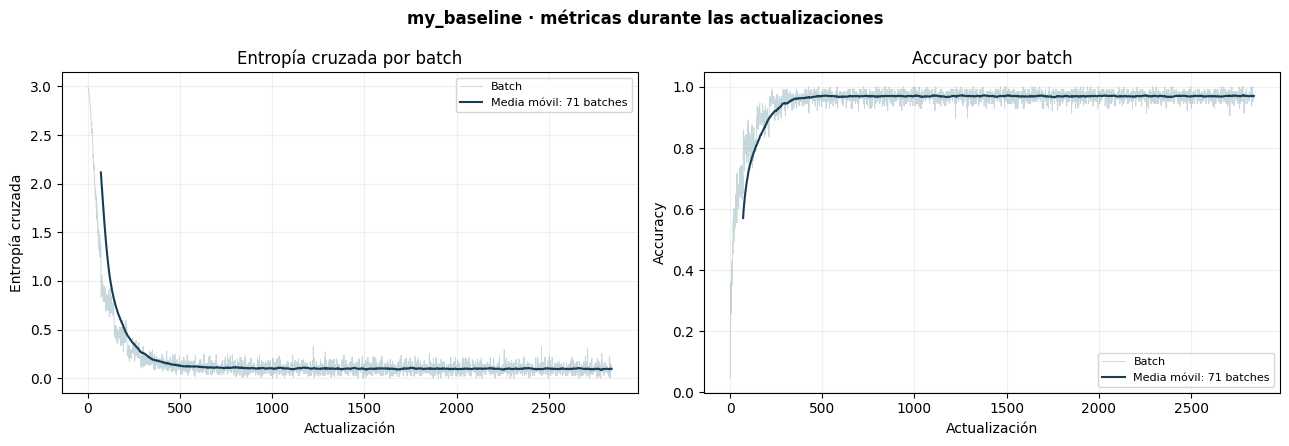

In [24]:
# my_baseline: muestra cómo varían la pérdida y la accuracy entre batches.
my_batches = np.genfromtxt(my_run_dir / "batches.csv", delimiter=",", names=True)
# La media móvil usa tantos batches como una época.
my_window = len(my_train_loader)
my_kernel = np.ones(my_window) / my_window
my_smooth_steps = my_batches["step"][my_window - 1:]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, key, title, ylabel in [
    (axes[0], "J_ce", "Entropía cruzada por batch", "Entropía cruzada"),
    (axes[1], "accuracy", "Accuracy por batch", "Accuracy"),
]:
    ax.plot(my_batches["step"], my_batches[key], color="#739da9", alpha=.4,
            linewidth=.65, label="Batch")
    ax.plot(my_smooth_steps, np.convolve(my_batches[key], my_kernel, mode="valid"),
            color="#153d55", linewidth=1.5, label=f"Media móvil: {my_window} batches")
    ax.set(title=title, xlabel="Actualización", ylabel=ylabel)
    ax.grid(alpha=.18)
    ax.legend(fontsize=8)
fig.suptitle("my_baseline · métricas durante las actualizaciones", fontweight="bold")
plt.tight_layout()
plt.show()



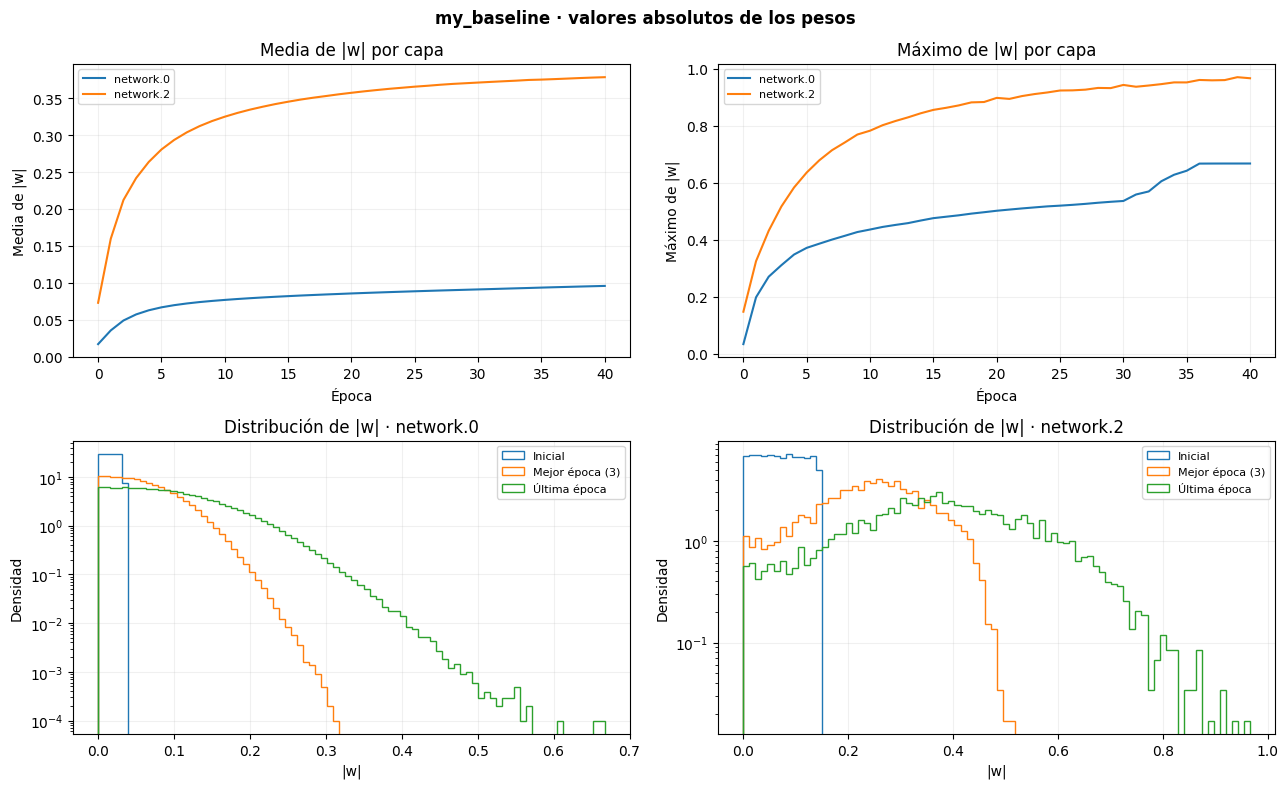

In [25]:
# my_baseline: compara la magnitud y la distribución de los pesos por capa.

my_initial_weights = torch.load(
    my_run_dir / "initial_weights.pt", map_location="cpu", weights_only=True
)
my_best_checkpoint = torch.load(
    my_run_dir / "model_best.pt", map_location="cpu", weights_only=True
)
my_last_checkpoint = torch.load(
    my_run_dir / "model_last.pt", map_location="cpu", weights_only=True
)

my_best_epoch = my_baseline_history["best_epoch"]
my_weight_names = list(my_baseline_history["initial_weights"])

fig, axes = plt.subplots(2, 2, figsize=(13, 8))

# La época 0 representa los pesos antes de entrenar.
for name in my_weight_names:
    initial = my_baseline_history["initial_weights"][name]
    by_epoch = [epoch[name] for epoch in my_baseline_history["weights"]]

    means = [initial["mean_abs"]] + [stats["mean_abs"] for stats in by_epoch]
    maxima = [initial["max_abs"]] + [stats["max_abs"] for stats in by_epoch]
    epochs = np.arange(len(means))

    axes[0, 0].plot(epochs, means, label=name)
    axes[0, 1].plot(epochs, maxima, label=name)

axes[0, 0].set(title="Media de |w| por capa", xlabel="Época", ylabel="Media de |w|")
axes[0, 1].set(title="Máximo de |w| por capa", xlabel="Época", ylabel="Máximo de |w|")

# Un histograma por capa para comparar el inicio, la mejor época y la última.
for ax, name in zip(axes[1], my_weight_names):
    # El archivo inicial usa el nombre de la capa. state_dict agrega ".weight".
    param_name = f"{name}.weight"
    saved_weights = [
        (my_initial_weights[name], "Inicial"),
        (my_best_checkpoint["state_dict"][param_name], f"Mejor época ({my_best_epoch})"),
        (my_last_checkpoint["state_dict"][param_name], "Última época"),
    ]

    # Aplanamos cada matriz para graficar todos sus pesos en un solo histograma.
    values = [(tensor.abs().numpy().ravel(), label) for tensor, label in saved_weights]

    # Usamos los mismos intervalos para los tres estados de la capa.
    upper = max(weights.max() for weights, _ in values)
    bins = np.linspace(0, upper if upper > 0 else 1.0, 85)

    for weights, label in values:
        ax.hist(weights, bins=bins, density=True, histtype="step", label=label)

    ax.set(title=f"Distribución de |w| · {name}", xlabel="|w|", ylabel="Densidad")
    ax.set_yscale("log")

for ax in axes.flat:
    ax.grid(alpha=0.18)
    ax.legend(fontsize=8)

fig.suptitle("my_baseline · valores absolutos de los pesos", fontweight="bold")
fig.tight_layout()
plt.show()

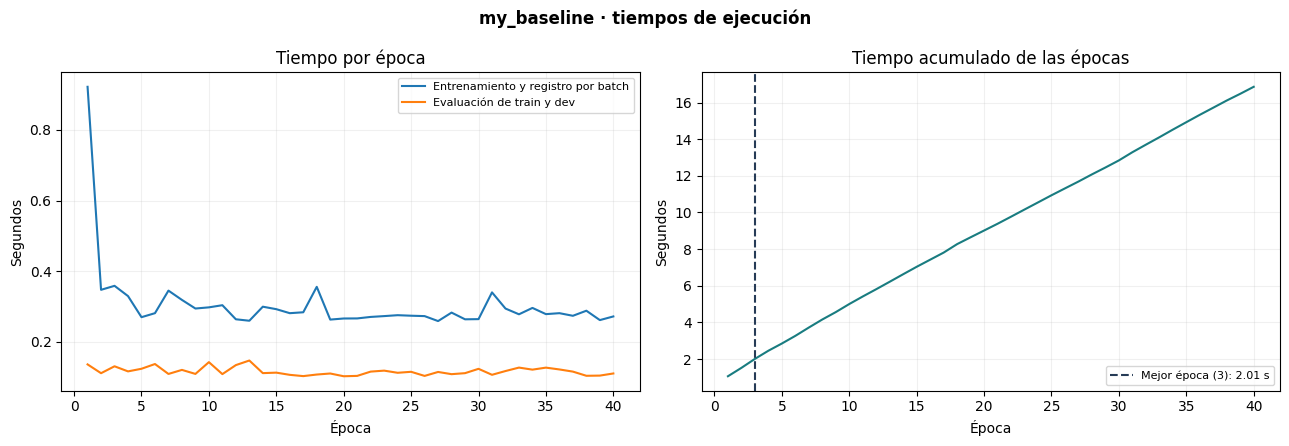

In [26]:
# my_baseline: separa los tiempos de entrenamiento y evaluación por época.

import numpy as np
import matplotlib.pyplot as plt

my_epochs = np.arange(1, my_baseline_history["epochs_completed"] + 1)
my_best_epoch = my_baseline_history["best_epoch"]
my_cumulative_seconds = np.cumsum(my_baseline_history["epoch_seconds"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Separamos actualizaciones y evaluación para ver dónde se consume el tiempo.
axes[0].plot(
    my_epochs, my_baseline_history["train_seconds"],
    label="Entrenamiento y registro por batch",
)
axes[0].plot(
    my_epochs, my_baseline_history["eval_seconds"],
    label="Evaluación de train y dev",
)
axes[0].set(title="Tiempo por época", xlabel="Época", ylabel="Segundos")

# Marcamos cuánto tiempo de épocas se acumuló hasta la mejor accuracy de dev.
seconds_at_best = my_cumulative_seconds[my_best_epoch - 1]
axes[1].plot(my_epochs, my_cumulative_seconds, color="#197c80")
axes[1].axvline(
    my_best_epoch, color="#263b56", linestyle="--",
    label=f"Mejor época ({my_best_epoch}): {seconds_at_best:.2f} s",
)
axes[1].set(title="Tiempo acumulado de las épocas", xlabel="Época", ylabel="Segundos")

for ax in axes:
    ax.grid(alpha=0.18)
    ax.legend(fontsize=8)

fig.suptitle("my_baseline · tiempos de ejecución", fontweight="bold")
fig.tight_layout()
plt.show()

### Análisis del baseline

Después de aplicar TF-IDF quedaron 5000 columnas. Hay 279 documentos de
train y 67 de dev sin términos en el vocabulario. Esas filas quedan en
cero y sus documentos se mantienen en la evaluación.

A partir de la época 3 se ve el sobreajuste. La accuracy de train sube de
94,43 % a 97,07 % y la de dev baja de 70,16 % a 66,80 %. En ese tramo la
pérdida baja en train y sube en dev. La media móvil suaviza las
fluctuaciones de las curvas por batch.

La media de los valores absolutos de los pesos crece en ambas capas.
La salida ya arranca con pesos más grandes en promedio (0,073 frente a
0,017). Xavier usa un intervalo más ancho cuando la suma de entradas y
salidas de la capa es menor.

## 7. Regularización controlada

Usamos la partición, el vectorizador y los pesos iniciales de `my_baseline`. Cada variante se entrena desde cero con un Adam nuevo, la misma semilla, batch 128, learning rate fijo y un máximo de 40 épocas. Comparamos la mejor época por accuracy de dev y la última de cada corrida. Con early stopping, la última es la época de corte.

En cada apartado mostramos curvas de entropía cruzada y accuracy, una tabla con métricas y tiempos, y la distribución de los pesos lineales en la última época. Para comparar el ruido, calculamos el desvío de la entropía cruzada entre batches en cada época. La tabla promedia ese desvío en las primeras cinco épocas y en las últimas cinco de cada corrida. Ejecutá las tres celdas compartidas antes de una subsección. Los barridos completos que coincidan con el baseline se cargan desde disco.

In [27]:
# Sección 7: carga el baseline y prepara una vez los datos para todos los experimentos.

import csv
import json
import time
from datetime import datetime
from pathlib import Path

import joblib
import pandas as pd

my_reg_project = Path.cwd()
if not (my_reg_project / "TP_Regularización.ipynb").is_file():
    my_reg_project = my_reg_project / "TP RN Regularización Bonacina"

my_reg_root = my_reg_project / ".experimentos"
my_reg_manifest = my_reg_root / "my_baseline" / "latest.json"
if not my_reg_manifest.is_file():
    raise FileNotFoundError("Hace falta una corrida guardada de my_baseline.")

my_reg_reference = json.loads(my_reg_manifest.read_text(encoding="utf-8"))
my_reg_baseline_dir = my_reg_manifest.parent / Path(my_reg_reference["run_dir"]).name
my_reg_config = json.loads((my_reg_baseline_dir / "config.json").read_text(encoding="utf-8"))
my_reg_baseline_history = json.loads(
    (my_reg_baseline_dir / "history.json").read_text(encoding="utf-8")
)
if (my_reg_config.get("split_id") != DATA_SPLIT_ID
    or my_reg_config["activation"] != ACTIVATION
    or my_reg_config["seed"] != SEED
    or my_reg_config["batch_size"] != BASELINE_BATCH_SIZE
    or my_reg_config["hidden_units"] != BASELINE_HIDDEN_UNITS
    or my_reg_config["lr"] != BASELINE_LR
    or my_reg_config["device"] != str(device)
    or my_reg_config["patience"] is not None
    or my_reg_baseline_history["epochs_completed"] != MAX_EPOCHS):
    raise ValueError("Volvé a correr la sección 6 para actualizar el baseline.")
my_reg_epochs = my_reg_baseline_history["epochs_completed"]

# Reutilizamos el vectorizador y los índices guardados con la referencia.
my_reg_prep_start = time.perf_counter()
my_reg_vectorizer = joblib.load(my_reg_baseline_dir / "vectorizer.joblib")
with np.load(my_reg_baseline_dir / "split_indices.npz") as indices:
    my_reg_train_indices, my_reg_dev_indices = indices["train"], indices["dev"]

assert len(my_reg_train_indices) == my_reg_config["train_documents"]
assert len(my_reg_dev_indices) == my_reg_config["dev_documents"]
assert np.array_equal(my_reg_train_indices, train_indices)
assert np.array_equal(my_reg_dev_indices, dev_indices)
my_reg_datasets = []
for indices in (my_reg_train_indices, my_reg_dev_indices):
    texts = [preprocess_text(newsgroups_train.data[i]) for i in indices]
    features = my_reg_vectorizer.transform(texts)
    my_reg_datasets.append(to_tensor_dataset(features, newsgroups_train.target[indices]))

my_reg_initial = torch.load(
    my_reg_baseline_dir / "initial_weights.pt", map_location="cpu", weights_only=True
)
my_reg_device = torch.device(my_reg_config["device"])
torch.set_num_threads(my_reg_config["cpu_threads"])
my_reg_preparation_seconds = time.perf_counter() - my_reg_prep_start
print(f"Preparación compartida: {my_reg_preparation_seconds:.2f} s")

Preparación compartida: 13.24 s


In [28]:
# Regularización: vuelve a entrenar desde el estado inicial del baseline.

def my_run_regularization(experiment, run_dir, experiment_id, name, settings):
    l1, l2 = settings["lambda_l1"], settings["lambda_l2"]
    dropout, batchnorm = settings["dropout"], settings["batchnorm"]
    patience = settings["patience"]
    folder = run_dir / name
    folder.mkdir()
    set_seed(my_reg_config["seed"])
    loaders = make_loaders(
        *my_reg_datasets, batch_size=my_reg_config["batch_size"], seed=my_reg_config["seed"],
        batchnorm=batchnorm,
    )
    model = my_MLP_model(
        input_dim=my_reg_config["input_dim"],
        num_classes=my_reg_config["num_classes"],
        hidden_units=my_reg_config["hidden_units"],
        activation_name=my_reg_config["activation"],
        dropout=dropout, batchnorm=batchnorm,
    ).to(my_reg_device)

    # BatchNorm y Dropout cambian los índices de Sequential. Emparejamos las capas lineales por orden.
    linears = [(key, layer) for key, layer in model.named_modules() if isinstance(layer, nn.Linear)]
    if len(linears) != len(my_reg_initial):
        raise ValueError("La arquitectura no coincide con las capas del baseline.")
    with torch.no_grad():
        for (_, layer), weight in zip(linears, my_reg_initial.values()):
            layer.weight.copy_(weight)

    optimizer = create_optimizer(
        model, my_reg_config["optimizer"], lr=my_reg_config["lr"],
        betas=(my_reg_config["beta1"], my_reg_config["beta2"]), weight_decay=0,
    )
    params = {
        **settings, "baseline": my_reg_baseline_dir.name,
        "seed": my_reg_config["seed"], "batch_size": my_reg_config["batch_size"],
        "epochs": my_reg_epochs, "activation": my_reg_config["activation"],
        "optimizer": my_reg_config["optimizer"], "lr": my_reg_config["lr"],
        "shared_preparation_seconds": my_reg_preparation_seconds,
    }
    tb_dir = my_reg_root / "tensorboard" / experiment / run_dir.name / name
    fields = ["step", "epoch", "batch", "examples", "J_ce", "J_total", "accuracy", "lr"]

    with SummaryWriter(log_dir=str(tb_dir)) as writer, (
        folder / "batches.csv"
    ).open("w", newline="", encoding="utf-8") as batch_file:
        batch_csv = csv.DictWriter(batch_file, fieldnames=fields)
        batch_csv.writeheader()

        def record_batch(epoch, batch, values):
            step = (epoch - 1) * len(loaders[0]) + batch
            batch_csv.writerow({"step": step, "epoch": epoch, "batch": batch, **values})
            writer.add_scalar("batches/J_ce", values["J_ce"], step)
            writer.add_scalar("batches/accuracy", values["accuracy"], step)

        def record_epoch(current_model, history):
            batch_file.flush()

        def save_last(current_model):
            # Se guarda antes de restaurar los pesos de la mejor época de dev.
            torch.save(current_model.state_dict(), folder / "model_last.pt")

        with mlflow.start_run(experiment_id=experiment_id, run_name=name):
            mlflow.log_params(params)
            history = train_mlp_model(
                model, *loaders, optimizer, epochs=my_reg_epochs, l1_lambda=l1, l2_lambda=l2,
                patience=patience, monitor="val_acc", restore_best=True,
                writer=writer, log_mlflow=True, run_name=name,
                batch_callback=record_batch, epoch_callback=record_epoch,
                last_epoch_callback=save_last,
            )
            torch.save(model.state_dict(), folder / "model_best.pt")
            (folder / "history.json").write_text(json.dumps(history, indent=2), encoding="utf-8")
            (folder / "config.json").write_text(json.dumps(params, indent=2), encoding="utf-8")
            mlflow.log_artifacts(str(folder))

    return {"history": history, "folder": folder, "config": params}

def my_load_regularization(folder, settings):
    required = ("config.json", "history.json", "batches.csv", "model_last.pt", "model_best.pt")
    if not all((folder / name).is_file() for name in required):
        return None
    config = json.loads((folder / "config.json").read_text(encoding="utf-8"))
    history = json.loads((folder / "history.json").read_text(encoding="utf-8"))
    if (config.get("baseline") != my_reg_baseline_dir.name
        or config.get("seed") != my_reg_config["seed"]
        or config.get("batch_size") != my_reg_config["batch_size"]
        or config.get("optimizer") != my_reg_config["optimizer"]
        or config.get("lr") != my_reg_config["lr"]
        or history.get("max_epochs") != my_reg_epochs
        or history.get("patience") != settings["patience"]
        or (history.get("epochs_completed") != my_reg_epochs and not history.get("stopped_early"))
        or any(config.get(key, 0) != value for key, value in settings.items() if key != "patience")):
        return None
    return {"history": history, "folder": folder, "config": {**config, **settings}}


def my_regularization_sweep(experiment, variants):
    root = my_reg_root / experiment
    saved = sorted((p for p in root.glob("*") if p.is_dir()), reverse=True)
    # Si ya existe este barrido con el mismo control, recuperamos sus resultados.
    for run_dir in saved:
        results = {}
        for label, settings in variants.items():
            result = my_load_regularization(run_dir / f"{experiment}_{label}", settings)
            if result is None:
                break
            results[label] = result
        if len(results) == len(variants):
            print(f"Corridas guardadas: {run_dir.name}")
            return run_dir, results

    run_dir = root / datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    run_dir.mkdir(parents=True, exist_ok=False)
    mlflow.set_tracking_uri("sqlite:///" + (my_reg_root / "mlflow.db").as_posix())
    client = mlflow.tracking.MlflowClient()
    existing = client.get_experiment_by_name(experiment)
    experiment_id = existing.experiment_id if existing else client.create_experiment(
        experiment, artifact_location=(my_reg_root / f"mlflow_artifacts_{experiment[3:]}").resolve().as_uri()
    )
    results = {
        label: my_run_regularization(
            experiment, run_dir, experiment_id, f"{experiment}_{label}", settings
        )
        for label, settings in variants.items()
    }
    return run_dir, results


def my_reg_settings(l1=0.0, l2=0.0, dropout=0.0, batchnorm=False, patience=None):
    return {
        "lambda_l1": l1, "lambda_l2": l2, "dropout": dropout,
        "batchnorm": batchnorm, "patience": patience,
    }

In [29]:
# Sección 7: muestra las mismas curvas y tablas para todas las técnicas.

def my_compare_regularization(results, run_dir):
    baseline = {
        "history": my_reg_baseline_history, "folder": my_reg_baseline_dir,
        "config": my_reg_settings(),
    }
    runs = {"Baseline": baseline, **results}
    colors = plt.get_cmap("tab10").colors
    fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
    metrics = [
        ("train_loss", "CE de train"), ("val_loss", "CE de dev"),
        ("train_acc", "Accuracy de train"), ("val_acc", "Accuracy de dev"),
    ]
    for ax, (key, title) in zip(axes.flat, metrics):
        marked = False
        for i, (label, result) in enumerate(runs.items()):
            history = result["history"]
            last_epoch = history["epochs_completed"]
            ax.plot(range(1, last_epoch + 1), history[key], label=label,
                    color="black" if i == 0 else colors[i - 1],
                    linestyle="--" if i == 0 else "-")
            if history["stopped_early"]:
                ax.plot(last_epoch, history[key][-1], marker="D", color="red",
                        linestyle="none", zorder=5,
                        label="Early stopping" if not marked else "_nolegend_")
                marked = True
        ax.set(title=title, xlabel="Época", xlim=(0.5, my_reg_epochs + 0.5))
        ax.grid(alpha=0.2)
    axes[0, 1].legend(fontsize=8)
    fig.tight_layout()
    plt.show()

    rows, noise_rows = [], []
    for label, result in runs.items():
        h, cfg = result["history"], result["config"]
        for moment, epoch in [("Mejor dev", h["best_epoch"]), ("Última", h["epochs_completed"])]:
            i = epoch - 1
            rows.append({
                "modelo": label, "λ₁": cfg["lambda_l1"], "λ₂": cfg["lambda_l2"],
                "dropout": cfg["dropout"], "BatchNorm": cfg["batchnorm"],
                "momento": moment, "época": epoch, "épocas hechas": h["epochs_completed"],
                "early stopping": h["stopped_early"],
                "accuracy train (%)": 100 * h["train_acc"][i],
                "accuracy dev (%)": 100 * h["val_acc"][i], "CE train": h["train_loss"][i],
                "CE dev": h["val_loss"][i], "brecha (pp)": 100 * h["gap_acc"][i],
                "s acumulados por época": sum(h["epoch_seconds"][:epoch]),
                "s del entrenador": h["total_seconds"],
            })
        batches = pd.read_csv(result["folder"] / "batches.csv")
        # Variación de CE dentro de cada época, medida sobre los batches de entrenamiento.
        spread = batches.groupby("epoch")["J_ce"].std(ddof=0)
        noise_rows.append({
            "modelo": label, "CE por batch · épocas 1–5": spread.loc[1:5].mean(),
            f"CE por batch · últimas {min(5, my_reg_epochs)} épocas": spread.tail(5).mean(),
        })

    weight_rows = []
    fig, axes = plt.subplots(1, len(my_reg_initial), figsize=(12, 4), squeeze=False)
    for i, (label, result) in enumerate(runs.items()):
        checkpoint = torch.load(
            result["folder"] / "model_last.pt", map_location="cpu", weights_only=True
        )
        state = checkpoint.get("state_dict", checkpoint)
        # history contiene solo capas lineales y respeta el orden de la red.
        layer_names = list(result["history"]["weights"][-1])
        for number, (ax, key) in enumerate(zip(axes.flat, layer_names), start=1):
            values = np.sort(state[f"{key}.weight"].abs().numpy().ravel())
            ax.plot(values, np.arange(1, len(values) + 1) / len(values), label=label,
                    color="black" if i == 0 else colors[i - 1],
                    linestyle="--" if i == 0 else "-")
            layer = "Salida" if number == len(layer_names) else f"Oculta {number}"
            weight_rows.append({
                "modelo": label, "capa": layer, "época": result["history"]["epochs_completed"],
                "media |w|": values.mean(),
                "máx. |w|": values.max(), "% con |w| < 0,001": 100 * np.mean(values < 1e-3),
            })
            ax.set(title=layer, xlabel="|w|", ylabel="Fracción acumulada")
    for ax in axes.flat:
        ax.axvline(1e-3, linestyle=":", color="gray", linewidth=1)
        ax.set_xscale("symlog", linthresh=1e-5)
        ax.grid(alpha=0.2)
    axes[0, 0].legend(fontsize=8)
    fig.suptitle("Distribución de pesos en la última época de cada corrida")
    fig.tight_layout()
    plt.show()

    weights_file = "pesos_ultima_epoca.csv" if any(
        r["history"]["stopped_early"] for r in runs.values()
    ) else f"pesos_epoca{my_reg_epochs}.csv"
    for records, filename in [
        (rows, "comparacion_seccion7.csv"), (weight_rows, weights_file), (noise_rows, "ruido_seccion7.csv"),
    ]:
        table = pd.DataFrame(records)
        shown = table.round(5)
        for column in ("λ₁", "λ₂"):
            if column in table:
                shown[column] = table[column].map(lambda value: f"{value:.0e}" if value else "0")
        display(shown)
        table.to_csv(run_dir / filename, index=False)

### 7.1 Regularización L1

Probamos $\lambda_1=10^{-6},10^{-5},10^{-4}$. Miramos qué proporción de pesos queda cerca de cero y cómo evoluciona la pérdida de dev.


In [30]:
# L1: prueba tres intensidades de L1.

my_l1_lambdas = [1e-6, 1e-5, 1e-4]
my_l1_run_dir, my_l1_runs = my_regularization_sweep(
    "my_l1", {f"{value:.0e}": my_reg_settings(l1=value) for value in my_l1_lambdas}
)


[my_l1_1e-06] 1/40 | train loss=1.0238 acc=0.8084 | dev loss=1.3053 acc=0.6932 | lr=0.0025 | entrenamiento=0.36s
[my_l1_1e-06] 2/40 | train loss=0.4961 acc=0.9009 | dev loss=1.0209 acc=0.6950 | lr=0.0025 | entrenamiento=0.38s
[my_l1_1e-06] 3/40 | train loss=0.2962 acc=0.9437 | dev loss=0.9945 acc=0.6985 | lr=0.0025 | entrenamiento=0.32s
[my_l1_1e-06] 4/40 | train loss=0.2024 acc=0.9625 | dev loss=1.0142 acc=0.6945 | lr=0.0025 | entrenamiento=0.31s
[my_l1_1e-06] 5/40 | train loss=0.1586 acc=0.9674 | dev loss=1.0554 acc=0.6866 | lr=0.0025 | entrenamiento=0.32s
[my_l1_1e-06] 6/40 | train loss=0.1358 acc=0.9686 | dev loss=1.0853 acc=0.6839 | lr=0.0025 | entrenamiento=0.33s
[my_l1_1e-06] 7/40 | train loss=0.1236 acc=0.9696 | dev loss=1.1198 acc=0.6857 | lr=0.0025 | entrenamiento=0.33s
[my_l1_1e-06] 8/40 | train loss=0.1163 acc=0.9703 | dev loss=1.1505 acc=0.6817 | lr=0.0025 | entrenamiento=0.36s
[my_l1_1e-06] 9/40 | train loss=0.1119 acc=0.9705 | dev loss=1.1785 acc=0.6786 | lr=0.0025 | ent

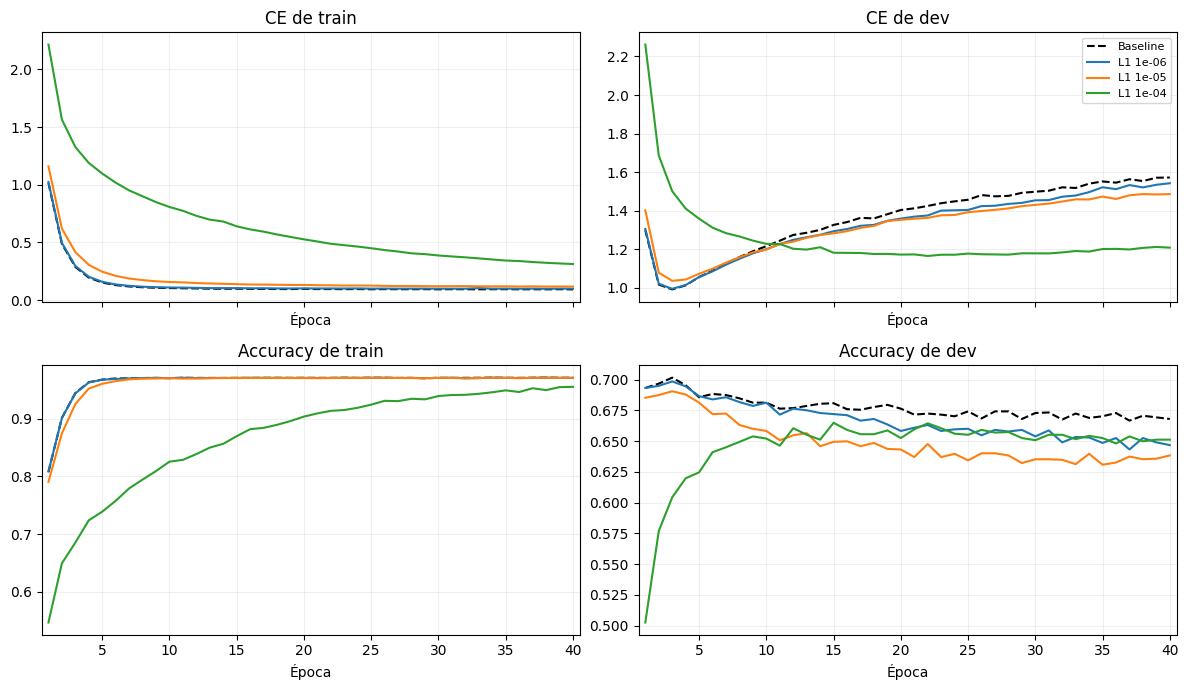

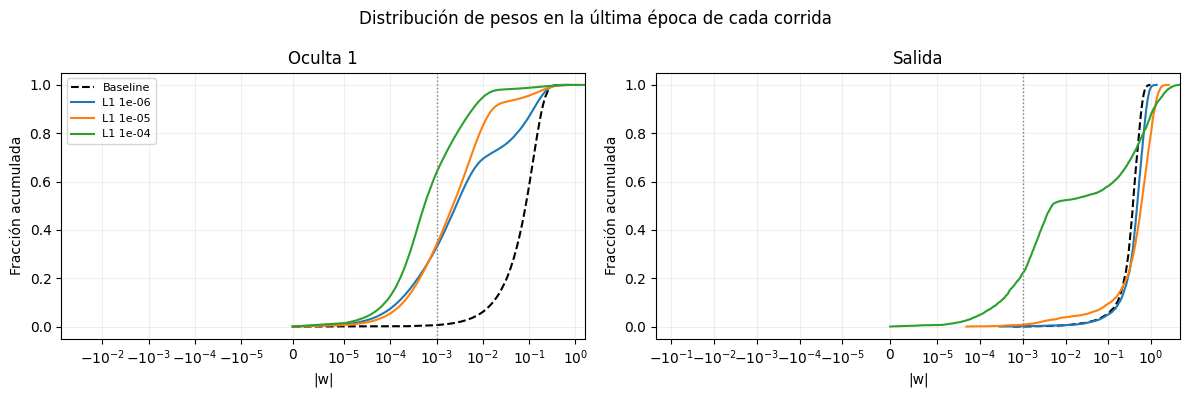

,modelo,λ₁,λ₂,dropout,BatchNorm,momento,época,épocas hechas,early stopping,accuracy train (%),accuracy dev (%),CE train,CE dev,brecha (pp),s acumulados por época,s del entrenador
0,Baseline,0,0,0.0,False,Mejor dev,3,40,False,94.43217,70.15915,0.28809,0.99152,24.27302,2.00710,17.82239
1,Baseline,0,0,0.0,False,Última,40,40,False,97.07247,66.79929,0.09280,1.57199,30.27318,16.86220,17.82239
2,L1 1e-06,1e-06,0,0.0,False,Mejor dev,3,40,False,94.36589,69.84969,0.29618,0.99455,24.51620,1.38864,18.89356
3,L1 1e-06,1e-06,0,0.0,False,Última,40,40,False,97.05038,64.67728,0.09875,1.54229,32.37310,18.02744,18.89356
4,L1 1e-05,1e-05,0,0.0,False,Mejor dev,3,40,False,92.52099,69.05393,0.41598,1.03603,23.46706,1.39491,18.04539
5,L1 1e-05,1e-05,0,0.0,False,Última,40,40,False,97.07247,63.83731,0.11691,1.48591,33.23516,17.20181,18.04539
6,L1 1e-04,1e-04,0,0.0,False,Mejor dev,15,40,False,86.96421,66.48983,0.63973,1.18181,20.47437,6.75591,17.96522
7,L1 1e-04,1e-04,0,0.0,False,Última,40,40,False,95.50376,65.11936,0.31263,1.20821,30.38439,17.07217,17.96522


,modelo,capa,época,media |w|,máx. |w|,"% con |w| < 0,001"
0,Baseline,Oculta 1,40,0.09573,0.66740,0.61008
1,Baseline,Salida,40,0.37844,0.96649,0.01953
2,L1 1e-06,Oculta 1,40,0.03294,0.72985,32.75523
3,L1 1e-06,Salida,40,0.47828,1.35034,0.13672
4,L1 1e-05,Oculta 1,40,0.01502,1.16642,33.93023
5,L1 1e-05,Salida,40,0.63758,2.59919,0.82031
6,L1 1e-04,Oculta 1,40,0.00528,1.54516,63.71922
7,L1 1e-04,Salida,40,0.36001,4.52422,22.18750


,modelo,CE por batch · épocas 1–5,CE por batch · últimas 5 épocas
0,Baseline,0.16728,0.04698
1,L1 1e-06,0.16656,0.04719
2,L1 1e-05,0.16430,0.04797
3,L1 1e-04,0.13674,0.06337


In [31]:
# L1: compara las tres intensidades con el baseline.

my_compare_regularization({f"L1 {label}": result for label, result in my_l1_runs.items()}, my_l1_run_dir)


Con semilla 3 se ve el efecto de L1 sobre los pesos. En la última época,
con $\lambda_1=10^{-4}$, el 63,7 % de los pesos de la capa oculta queda
con $|w|<10^{-3}$, frente al 32,8–33,9 % con los otros dos valores. Para
un peso distinto de cero, L1 aporta $\lambda_1 \operatorname{sign}(w_i)$
al gradiente.

Con $10^{-4}$ la accuracy de train al final es menor y la de dev queda
por encima de las otras variantes L1 en la época 40. Su mejor accuracy de
dev fue la más baja de las tres (66,49 %), y ninguna superó el 70,16 % del
baseline. Dejé correr las 40 épocas para observar la evolución.

### 7.2 Regularización L2

Probamos $\lambda_2=10^{-5},10^{-4},10^{-3}$. La penalización cuadrática se suma a $J$ y Adam usa `weight_decay=0`.


In [32]:
# L2: prueba tres intensidades de L2.

my_l2_lambdas = [1e-5, 1e-4, 1e-3]
my_l2_run_dir, my_l2_runs = my_regularization_sweep(
    "my_l2", {f"{value:.0e}": my_reg_settings(l2=value) for value in my_l2_lambdas}
)


[my_l2_1e-05] 1/40 | train loss=1.0196 acc=0.8078 | dev loss=1.3024 acc=0.6936 | lr=0.0025 | entrenamiento=0.39s
[my_l2_1e-05] 2/40 | train loss=0.4961 acc=0.9011 | dev loss=1.0223 acc=0.6972 | lr=0.0025 | entrenamiento=0.39s
[my_l2_1e-05] 3/40 | train loss=0.2985 acc=0.9435 | dev loss=0.9968 acc=0.7007 | lr=0.0025 | entrenamiento=0.33s
[my_l2_1e-05] 4/40 | train loss=0.2059 acc=0.9627 | dev loss=1.0165 acc=0.6914 | lr=0.0025 | entrenamiento=0.33s
[my_l2_1e-05] 5/40 | train loss=0.1628 acc=0.9674 | dev loss=1.0564 acc=0.6870 | lr=0.0025 | entrenamiento=0.41s
[my_l2_1e-05] 6/40 | train loss=0.1403 acc=0.9683 | dev loss=1.0853 acc=0.6844 | lr=0.0025 | entrenamiento=0.35s
[my_l2_1e-05] 7/40 | train loss=0.1282 acc=0.9695 | dev loss=1.1171 acc=0.6848 | lr=0.0025 | entrenamiento=0.33s
[my_l2_1e-05] 8/40 | train loss=0.1210 acc=0.9703 | dev loss=1.1448 acc=0.6804 | lr=0.0025 | entrenamiento=0.31s
[my_l2_1e-05] 9/40 | train loss=0.1167 acc=0.9705 | dev loss=1.1704 acc=0.6746 | lr=0.0025 | ent

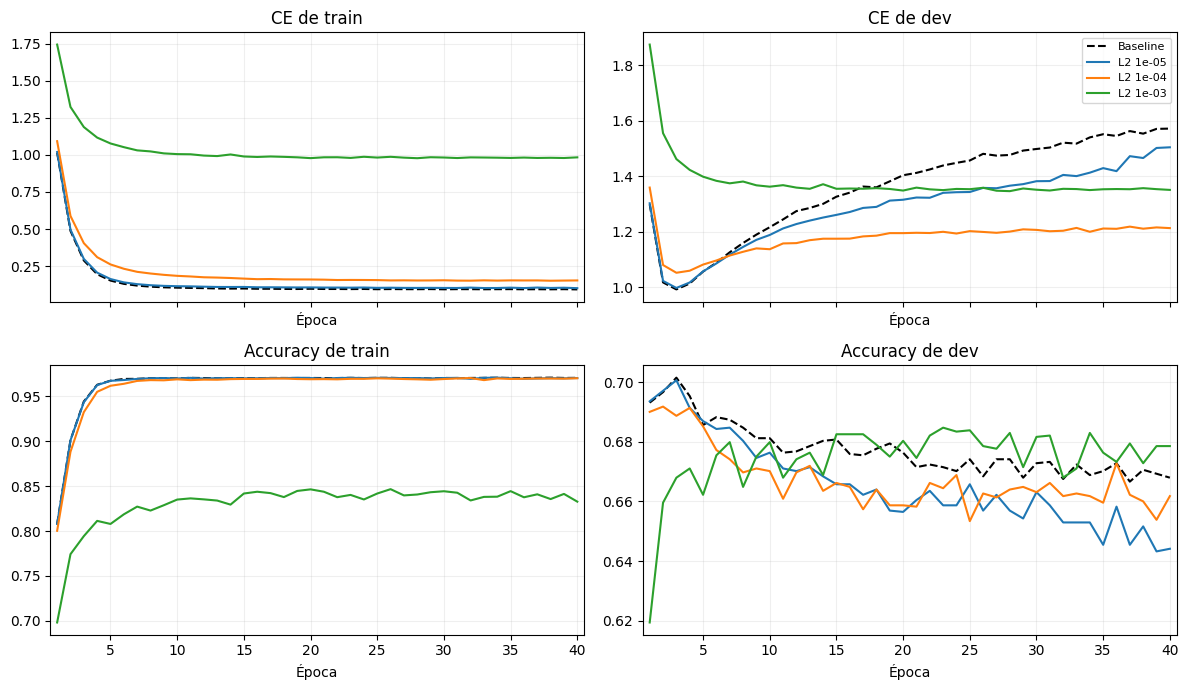

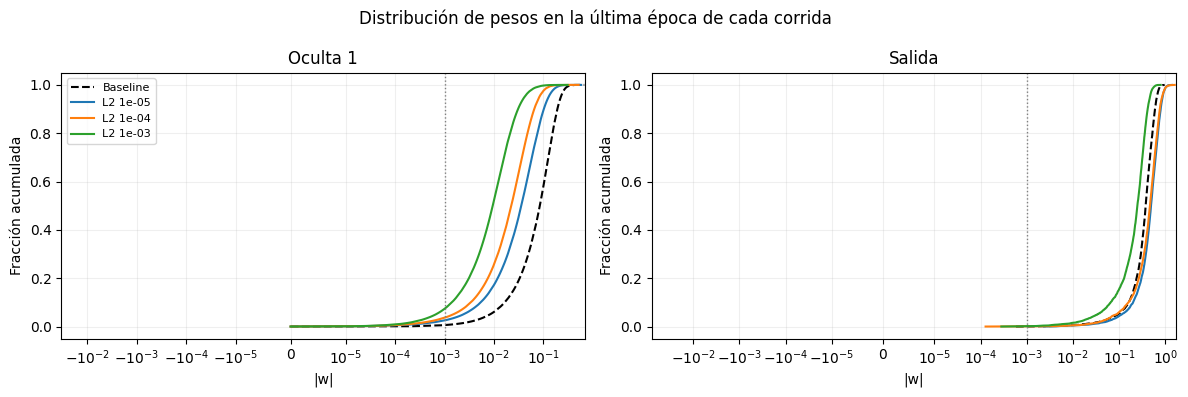

,modelo,λ₁,λ₂,dropout,BatchNorm,momento,época,épocas hechas,early stopping,accuracy train (%),accuracy dev (%),CE train,CE dev,brecha (pp),s acumulados por época,s del entrenador
0,Baseline,0,0,0.0,False,Mejor dev,3,40,False,94.43217,70.15915,0.28809,0.99152,24.27302,2.00710,17.82239
1,Baseline,0,0,0.0,False,Última,40,40,False,97.07247,66.79929,0.09280,1.57199,30.27318,16.86220,17.82239
2,L2 1e-05,0,1e-05,0.0,False,Mejor dev,3,40,False,94.35484,70.07073,0.29847,0.99680,24.28410,1.44919,18.98406
3,L2 1e-05,0,1e-05,0.0,False,Última,40,40,False,97.05038,64.41202,0.10127,1.50449,32.63835,18.09468,18.98406
4,L2 1e-04,0,1e-04,0.0,False,Mejor dev,2,40,False,88.83120,69.18656,0.58839,1.07952,19.64464,0.89206,21.07960
5,L2 1e-04,0,1e-04,0.0,False,Última,40,40,False,97.02828,66.18037,0.15338,1.21278,30.84791,20.08995,21.07960
6,L2 1e-03,0,1e-03,0.0,False,Mejor dev,23,40,False,84.02563,68.47922,0.97974,1.34995,15.54641,10.87135,19.42832
7,L2 1e-03,0,1e-03,0.0,False,Última,40,40,False,83.27441,67.86030,0.98357,1.35069,15.41411,18.55182,19.42832


,modelo,capa,época,media |w|,máx. |w|,"% con |w| < 0,001"
0,Baseline,Oculta 1,40,0.09573,0.66740,0.61008
1,Baseline,Salida,40,0.37844,0.96649,0.01953
2,L2 1e-05,Oculta 1,40,0.04624,0.57657,2.53312
3,L2 1e-05,Salida,40,0.49595,1.39576,0.00000
4,L2 1e-04,Oculta 1,40,0.02954,0.51367,3.65805
5,L2 1e-04,Salida,40,0.46730,1.59177,0.05859
6,L2 1e-03,Oculta 1,40,0.01369,0.30788,7.34031
7,L2 1e-03,Salida,40,0.24734,0.79112,0.15625


,modelo,CE por batch · épocas 1–5,CE por batch · últimas 5 épocas
0,Baseline,0.16728,0.04698
1,L2 1e-05,0.16677,0.04845
2,L2 1e-04,0.16776,0.05703
3,L2 1e-03,0.14877,0.10896


In [33]:
# L2: compara las tres intensidades con el baseline.

my_compare_regularization({f"L2 {label}": result for label, result in my_l2_runs.items()}, my_l2_run_dir)


Con L2 sumamos $\lambda_2 \sum_i w_i^2$ al costo. El aporte al gradiente
de cada peso es $2\lambda_2 w_i$, así que la penalización empuja más a
los pesos grandes. En la capa oculta se ve que la media de $|w|$ baja
cuando sube $\lambda_2$.

Entre las tres variantes L2, la brecha de train a dev en la época 40
bajó de 32,64 a 30,85 y luego a 15,41 puntos. Con $\lambda_2=10^{-3}$,
train bajó a 83,27 % y dev terminó en 67,86 %. Esa variante sostuvo mejor
dev hasta el final, aunque su pico quedó por debajo del baseline.

### 7.3 Regularización L1 + L2

Fijamos $\lambda_1=10^{-6}$ y usamos las tres intensidades de 7.2. Comparamos cada combinación con L2 al mismo $\lambda_2$.


In [34]:
# L1 + L2: combina L1 fijo con las tres intensidades de L2.

my_l1_l2_run_dir, my_l1_l2_runs = my_regularization_sweep(
    "my_l1_l2", {
        f"{value:.0e}": my_reg_settings(l1=1e-6, l2=value)
        for value in my_l2_lambdas
    }
)


[my_l1_l2_1e-05] 1/40 | train loss=1.0322 acc=0.8062 | dev loss=1.3116 acc=0.6910 | lr=0.0025 | entrenamiento=0.40s
[my_l1_l2_1e-05] 2/40 | train loss=0.5065 acc=0.8999 | dev loss=1.0271 acc=0.6954 | lr=0.0025 | entrenamiento=0.37s
[my_l1_l2_1e-05] 3/40 | train loss=0.3079 acc=0.9423 | dev loss=1.0003 acc=0.6972 | lr=0.0025 | entrenamiento=0.37s
[my_l1_l2_1e-05] 4/40 | train loss=0.2140 acc=0.9620 | dev loss=1.0192 acc=0.6914 | lr=0.0025 | entrenamiento=0.36s
[my_l1_l2_1e-05] 5/40 | train loss=0.1699 acc=0.9670 | dev loss=1.0579 acc=0.6866 | lr=0.0025 | entrenamiento=0.36s
[my_l1_l2_1e-05] 6/40 | train loss=0.1468 acc=0.9680 | dev loss=1.0865 acc=0.6804 | lr=0.0025 | entrenamiento=0.45s
[my_l1_l2_1e-05] 7/40 | train loss=0.1343 acc=0.9695 | dev loss=1.1177 acc=0.6830 | lr=0.0025 | entrenamiento=0.37s
[my_l1_l2_1e-05] 8/40 | train loss=0.1268 acc=0.9702 | dev loss=1.1450 acc=0.6790 | lr=0.0025 | entrenamiento=0.40s
[my_l1_l2_1e-05] 9/40 | train loss=0.1223 acc=0.9705 | dev loss=1.1704 a

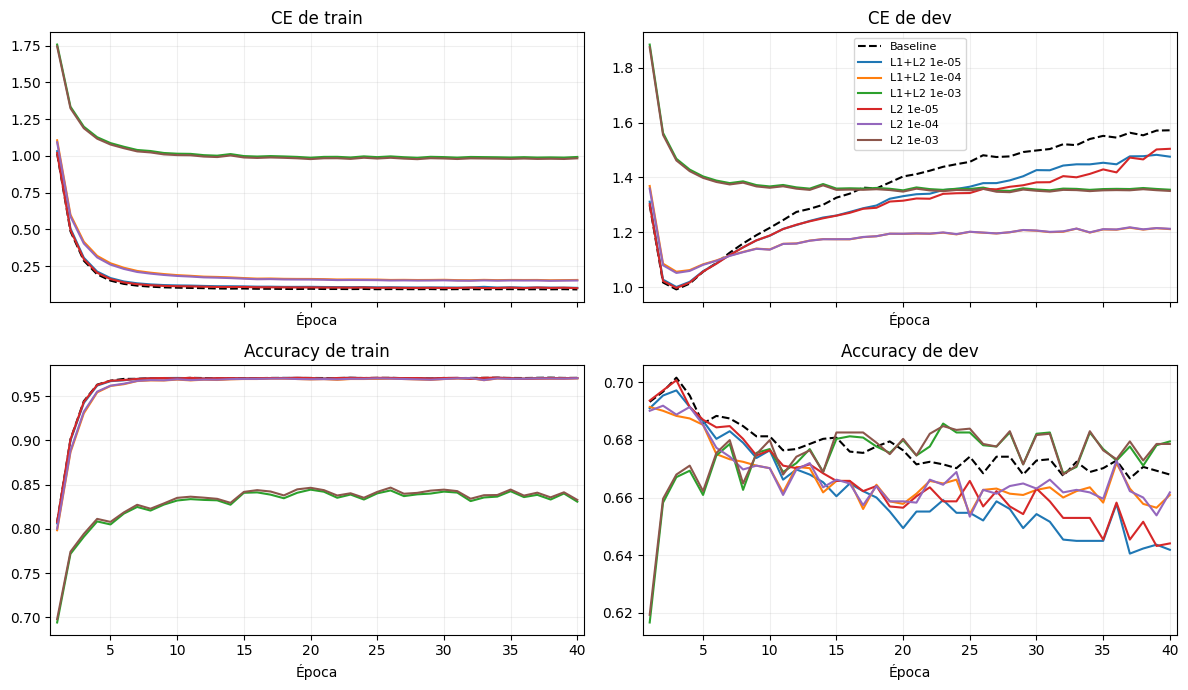

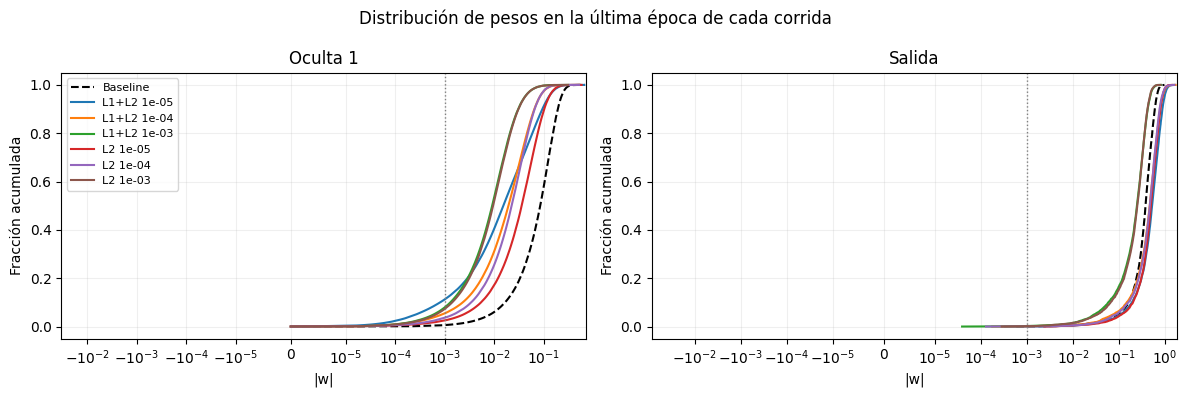

,modelo,λ₁,λ₂,dropout,BatchNorm,momento,época,épocas hechas,early stopping,accuracy train (%),accuracy dev (%),CE train,CE dev,brecha (pp),s acumulados por época,s del entrenador
0,Baseline,0,0,0.0,False,Mejor dev,3,40,False,94.43217,70.15915,0.28809,0.99152,24.27302,2.00710,17.82239
1,Baseline,0,0,0.0,False,Última,40,40,False,97.07247,66.79929,0.09280,1.57199,30.27318,16.86220,17.82239
2,L1+L2 1e-05,1e-06,1e-05,0.0,False,Mejor dev,3,40,False,94.23332,69.71706,0.30794,1.00032,24.51625,1.52868,22.04082
3,L1+L2 1e-05,1e-06,1e-05,0.0,False,Última,40,40,False,97.03933,64.19098,0.10359,1.47577,32.84835,21.11523,22.04082
4,L1+L2 1e-04,1e-06,1e-04,0.0,False,Mejor dev,1,40,False,79.84976,69.14235,1.10620,1.36882,10.70741,0.58701,22.07367
5,L1+L2 1e-04,1e-06,1e-04,0.0,False,Última,40,40,False,97.01723,66.09195,0.15695,1.21151,30.92528,21.06389,22.07367
6,L1+L2 1e-03,1e-06,1e-03,0.0,False,Mejor dev,23,40,False,83.88202,68.56764,0.98928,1.35469,15.31438,12.39947,22.46069
7,L1+L2 1e-03,1e-06,1e-03,0.0,False,Última,40,40,False,83.07556,67.94872,0.99289,1.35530,15.12685,21.52930,22.46069
8,L2 1e-05,0,1e-05,0.0,False,Mejor dev,3,40,False,94.35484,70.07073,0.29847,0.99680,24.28410,1.44919,18.98406
9,L2 1e-05,0,1e-05,0.0,False,Última,40,40,False,97.05038,64.41202,0.10127,1.50449,32.63835,18.09468,18.98406


,modelo,capa,época,media |w|,máx. |w|,"% con |w| < 0,001"
0,Baseline,Oculta 1,40,0.09573,0.66740,0.61008
1,Baseline,Salida,40,0.37844,0.96649,0.01953
2,L1+L2 1e-05,Oculta 1,40,0.03331,0.65199,11.28883
3,L1+L2 1e-05,Salida,40,0.53160,1.62317,0.03906
4,L1+L2 1e-04,Oculta 1,40,0.02760,0.52591,5.49945
5,L1+L2 1e-04,Salida,40,0.46862,1.68540,0.09766
6,L1+L2 1e-03,Oculta 1,40,0.01338,0.31373,7.98031
7,L1+L2 1e-03,Salida,40,0.24483,0.80846,0.19531
8,L2 1e-05,Oculta 1,40,0.04624,0.57657,2.53312
9,L2 1e-05,Salida,40,0.49595,1.39576,0.00000


,modelo,CE por batch · épocas 1–5,CE por batch · últimas 5 épocas
0,Baseline,0.16728,0.04698
1,L1+L2 1e-05,0.16614,0.04820
2,L1+L2 1e-04,0.16797,0.05810
3,L1+L2 1e-03,0.14798,0.10848
4,L2 1e-05,0.16677,0.04845
5,L2 1e-04,0.16776,0.05703
6,L2 1e-03,0.14877,0.10896


In [35]:
# L1 + L2: compara la combinación con el baseline y con L2 solo.

my_l1_l2_comparison = {f"L1+L2 {label}": result for label, result in my_l1_l2_runs.items()}
my_l1_l2_comparison.update({f"L2 {label}": result for label, result in my_l2_runs.items()})
my_compare_regularization(my_l1_l2_comparison, my_l1_l2_run_dir)


Con $\lambda_2=10^{-5}$, sumar L1 cambió el mejor resultado en dev de
70,07 % a 69,72 %. Con $\lambda_2=10^{-3}$, la combinación terminó con
67,95 % en dev frente a 67,86 % de L2 sola. En este barrido, sumar L1
produjo diferencias chicas y su efecto en accuracy dependió del valor de L2.

### 7.4 Dropout

Comparamos el baseline con Dropout en la capa oculta, después de LeakyReLU. Probamos `p=0.2`, `0.3` y `0.5`. L1, L2 y BatchNorm quedan desactivados.

In [36]:
# Dropout: prueba tres probabilidades en la capa oculta.

my_dropout_run_dir, my_dropout_runs = my_regularization_sweep(
    "my_dropout", {str(p): my_reg_settings(dropout=p) for p in (0.2, 0.3, 0.5)}
)


[my_dropout_0.2] 1/40 | train loss=1.1071 acc=0.8010 | dev loss=1.3656 acc=0.6901 | lr=0.0025 | entrenamiento=0.31s
[my_dropout_0.2] 2/40 | train loss=0.5460 acc=0.8900 | dev loss=1.0279 acc=0.6972 | lr=0.0025 | entrenamiento=0.36s
[my_dropout_0.2] 3/40 | train loss=0.3337 acc=0.9349 | dev loss=0.9864 acc=0.6981 | lr=0.0025 | entrenamiento=0.35s
[my_dropout_0.2] 4/40 | train loss=0.2258 acc=0.9577 | dev loss=0.9944 acc=0.6976 | lr=0.0025 | entrenamiento=0.34s
[my_dropout_0.2] 5/40 | train loss=0.1716 acc=0.9652 | dev loss=1.0308 acc=0.6958 | lr=0.0025 | entrenamiento=0.36s
[my_dropout_0.2] 6/40 | train loss=0.1419 acc=0.9675 | dev loss=1.0592 acc=0.6861 | lr=0.0025 | entrenamiento=0.36s
[my_dropout_0.2] 7/40 | train loss=0.1257 acc=0.9691 | dev loss=1.0950 acc=0.6857 | lr=0.0025 | entrenamiento=0.35s
[my_dropout_0.2] 8/40 | train loss=0.1162 acc=0.9701 | dev loss=1.1285 acc=0.6835 | lr=0.0025 | entrenamiento=0.35s
[my_dropout_0.2] 9/40 | train loss=0.1100 acc=0.9704 | dev loss=1.1609 a

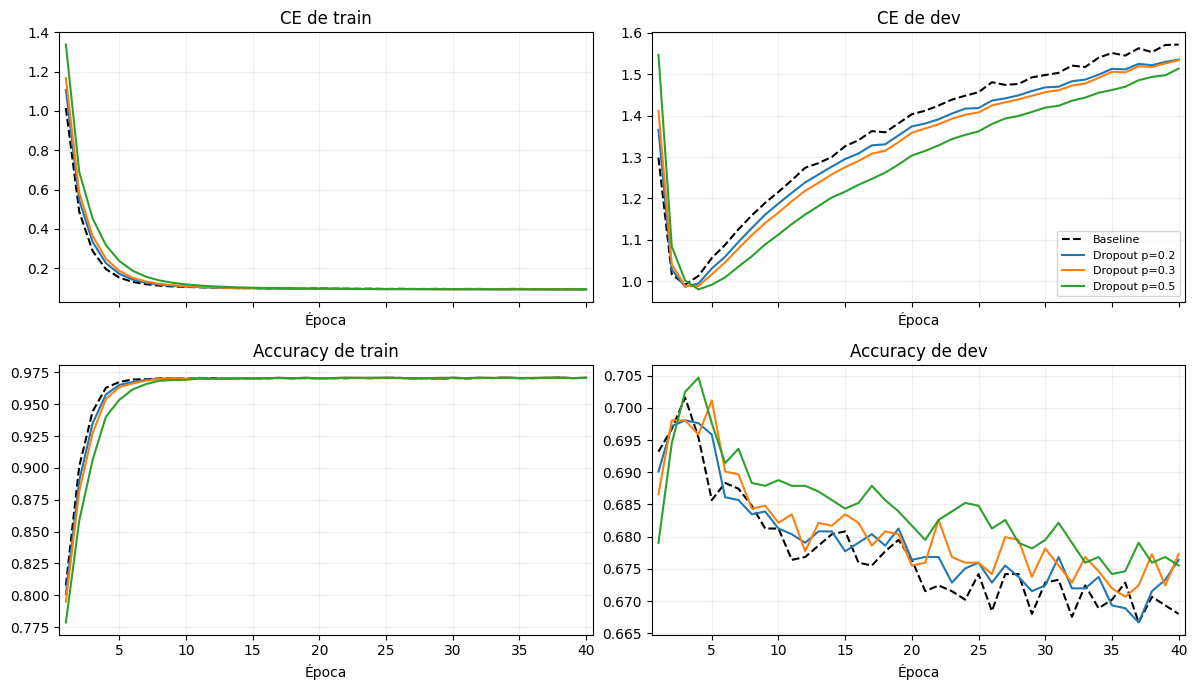

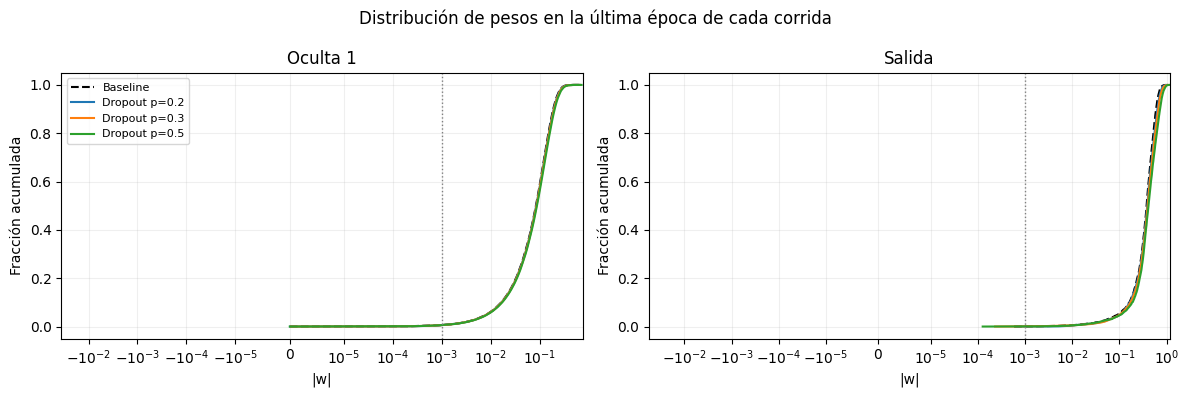

,modelo,λ₁,λ₂,dropout,BatchNorm,momento,época,épocas hechas,early stopping,accuracy train (%),accuracy dev (%),CE train,CE dev,brecha (pp),s acumulados por época,s del entrenador
0,Baseline,0,0,0.0,False,Mejor dev,3,40,False,94.43217,70.15915,0.28809,0.99152,24.27302,2.00710,17.82239
1,Baseline,0,0,0.0,False,Última,40,40,False,97.07247,66.79929,0.09280,1.57199,30.27318,16.86220,17.82239
2,Dropout p=0.2,0,0,0.2,False,Mejor dev,3,40,False,93.49315,69.80548,0.33365,0.98641,23.68767,1.38351,21.17826
3,Dropout p=0.2,0,0,0.2,False,Última,40,40,False,97.08352,67.63926,0.09226,1.53571,29.44426,20.20914,21.17826
4,Dropout p=0.3,0,0,0.3,False,Mejor dev,5,40,False,96.35440,70.11494,0.18635,1.01653,26.23945,2.49764,19.21537
5,Dropout p=0.3,0,0,0.3,False,Última,40,40,False,97.09456,67.72767,0.09206,1.53409,29.36689,18.32453,19.21537
6,Dropout p=0.5,0,0,0.5,False,Mejor dev,4,40,False,94.02342,70.46861,0.31708,0.98008,23.55481,1.93356,24.72299
7,Dropout p=0.5,0,0,0.5,False,Última,40,40,False,97.08352,67.55084,0.09218,1.51394,29.53268,23.60805,24.72299


,modelo,capa,época,media |w|,máx. |w|,"% con |w| < 0,001"
0,Baseline,Oculta 1,40,0.09573,0.66740,0.61008
1,Baseline,Salida,40,0.37844,0.96649,0.01953
2,Dropout p=0.2,Oculta 1,40,0.09762,0.65699,0.59359
3,Dropout p=0.2,Salida,40,0.39651,0.99867,0.01953
4,Dropout p=0.3,Oculta 1,40,0.09878,0.66326,0.60266
5,Dropout p=0.3,Salida,40,0.40800,1.03935,0.07812
6,Dropout p=0.5,Oculta 1,40,0.10157,0.72277,0.58844
7,Dropout p=0.5,Salida,40,0.43527,1.13320,0.03906


,modelo,CE por batch · épocas 1–5,CE por batch · últimas 5 épocas
0,Baseline,0.16728,0.04698
1,Dropout p=0.2,0.16555,0.04625
2,Dropout p=0.3,0.16511,0.04650
3,Dropout p=0.5,0.16192,0.04653


In [37]:
# Dropout: compara cada probabilidad con el baseline.

my_compare_regularization(
    {f"Dropout p={label}": result for label, result in my_dropout_runs.items()}, my_dropout_run_dir
)


Con semilla 3, el mejor resultado en dev fue con `p=0.5` en la época 4 (70,47 % frente al 70,16 % del baseline). En la época 40, los tres valores de Dropout quedaron por encima del baseline en accuracy de dev y por debajo en pérdida. `p=0.3` terminó con la mejor accuracy de dev (67,73 %). Con los tres valores todavía se ve sobreajuste.

En la tabla de pesos, la media de $|w|$ subió en ambas capas, sobre todo en la salida. La variación de la pérdida entre batches fue similar en las cuatro corridas.

### 7.5 Batch Normalization

Agregamos BatchNorm antes de LeakyReLU en la capa oculta. Se conserva la inicialización de las capas lineales y se quita el sesgo de la capa que precede a BatchNorm. L1, L2 y Dropout quedan desactivados.

In [38]:
# BatchNorm: entrena el baseline con BatchNorm en la capa oculta.

my_batchnorm_run_dir, my_batchnorm_runs = my_regularization_sweep(
    "my_batchnorm", {"solo": my_reg_settings(batchnorm=True)}
)


[my_batchnorm_solo] 1/40 | train loss=0.3105 acc=0.9434 | dev loss=1.0643 acc=0.6799 | lr=0.0025 | entrenamiento=0.67s
[my_batchnorm_solo] 2/40 | train loss=0.1260 acc=0.9692 | dev loss=1.1193 acc=0.6790 | lr=0.0025 | entrenamiento=0.57s
[my_batchnorm_solo] 3/40 | train loss=0.1058 acc=0.9697 | dev loss=1.2032 acc=0.6706 | lr=0.0025 | entrenamiento=0.55s
[my_batchnorm_solo] 4/40 | train loss=0.0993 acc=0.9700 | dev loss=1.2442 acc=0.6711 | lr=0.0025 | entrenamiento=0.55s
[my_batchnorm_solo] 5/40 | train loss=0.0965 acc=0.9706 | dev loss=1.2793 acc=0.6693 | lr=0.0025 | entrenamiento=0.58s
[my_batchnorm_solo] 6/40 | train loss=0.0970 acc=0.9707 | dev loss=1.2999 acc=0.6702 | lr=0.0025 | entrenamiento=0.63s
[my_batchnorm_solo] 7/40 | train loss=0.0952 acc=0.9704 | dev loss=1.3170 acc=0.6680 | lr=0.0025 | entrenamiento=0.62s
[my_batchnorm_solo] 8/40 | train loss=0.0948 acc=0.9707 | dev loss=1.3400 acc=0.6631 | lr=0.0025 | entrenamiento=0.55s
[my_batchnorm_solo] 9/40 | train loss=0.0951 acc

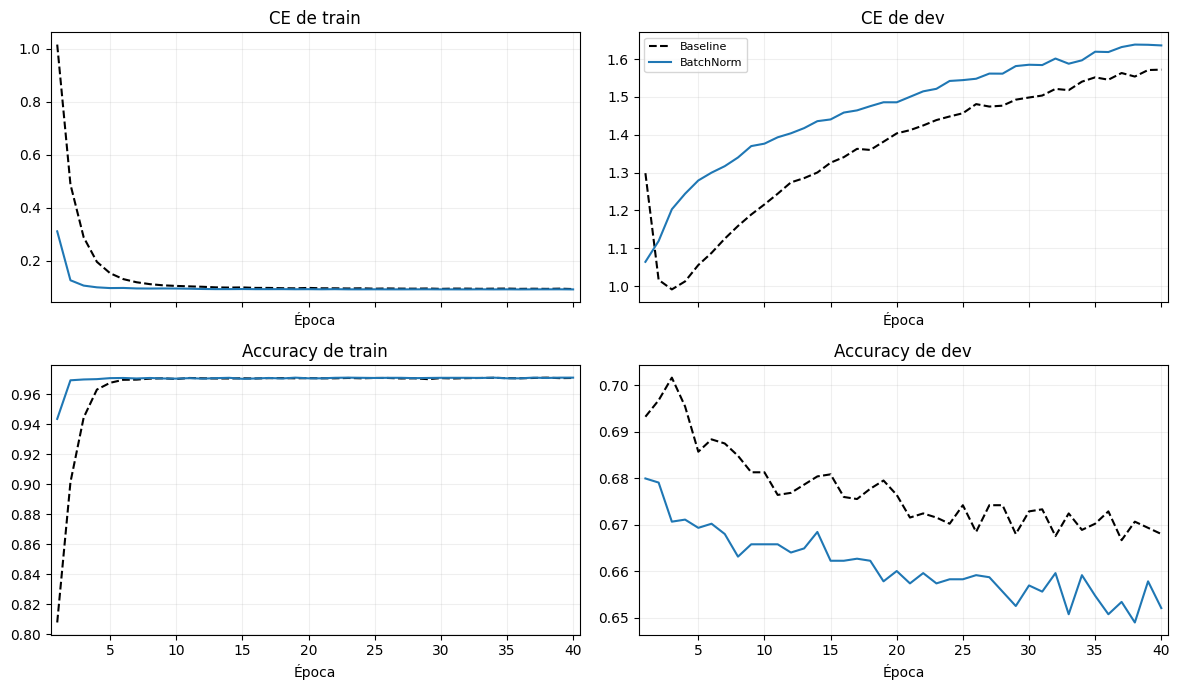

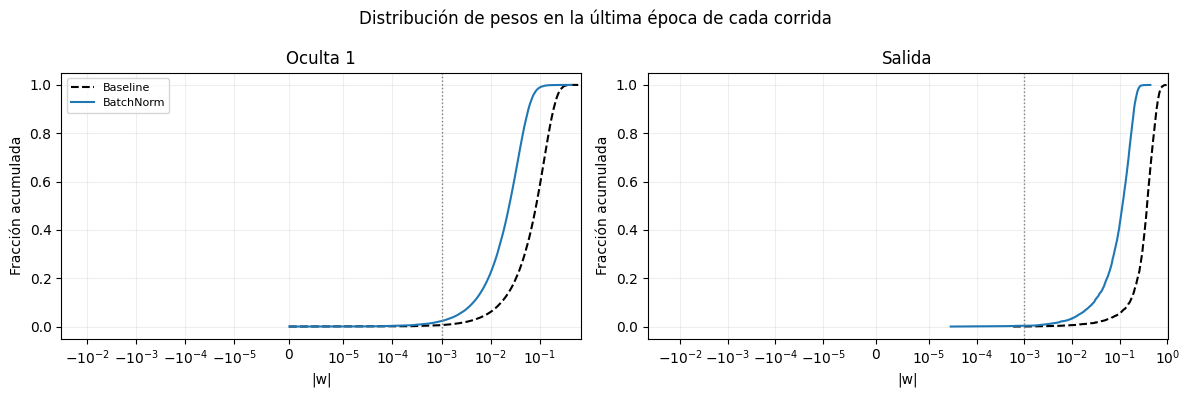

,modelo,λ₁,λ₂,dropout,BatchNorm,momento,época,épocas hechas,early stopping,accuracy train (%),accuracy dev (%),CE train,CE dev,brecha (pp),s acumulados por época,s del entrenador
0,Baseline,0,0,0.0,False,Mejor dev,3,40,False,94.43217,70.15915,0.28809,0.99152,24.27302,2.00710,17.82239
1,Baseline,0,0,0.0,False,Última,40,40,False,97.07247,66.79929,0.09280,1.57199,30.27318,16.86220,17.82239
2,BatchNorm,0,0,0.0,True,Mejor dev,1,40,False,94.34379,67.99293,0.31051,1.06432,26.35086,0.91384,31.64141
3,BatchNorm,0,0,0.0,True,Última,40,40,False,97.09456,65.20778,0.09152,1.63598,31.88678,30.19969,31.64141


,modelo,capa,época,media |w|,máx. |w|,"% con |w| < 0,001"
0,Baseline,Oculta 1,40,0.09573,0.66740,0.61008
1,Baseline,Salida,40,0.37844,0.96649,0.01953
2,BatchNorm,Oculta 1,40,0.02869,0.44311,2.26234
3,BatchNorm,Salida,40,0.11606,0.44075,0.35156


,modelo,CE por batch · épocas 1–5,CE por batch · últimas 5 épocas
0,Baseline,0.16728,0.04698
1,BatchNorm,0.13022,0.04588


In [39]:
# BatchNorm: compara la corrida con el baseline.

my_compare_regularization({"BatchNorm": my_batchnorm_runs["solo"]}, my_batchnorm_run_dir)


Con semilla 3, BatchNorm llegó a 94,34 % en train en la primera época. En esa misma época alcanzó su mejor accuracy de dev (67,99 %). Después sigue mejorando en train, mientras que en dev baja a 65,21 %. Así termina con una brecha de 31,89 puntos, un poco mayor que los 30,27 del baseline.

BatchNorm pudo facilitar el ajuste en train al normalizar las activaciones. En esta corrida eso vino acompañado de una mayor brecha al final. La media de $|w|$ bajó en ambas capas, pero con BatchNorm también intervienen la normalización y la escala aprendida. Para ver el sobreajuste, miré la brecha y la caída en dev.

### 7.6 Early stopping

Repetimos el baseline con una paciencia de 15 épocas sin mejorar la
accuracy de dev. El rombo rojo marca el corte. Al terminar recuperamos
los pesos de la mejor época. Se puede cambiar `patience` a mano en la
celda siguiente.

Corridas guardadas: 20261122_234521_333231


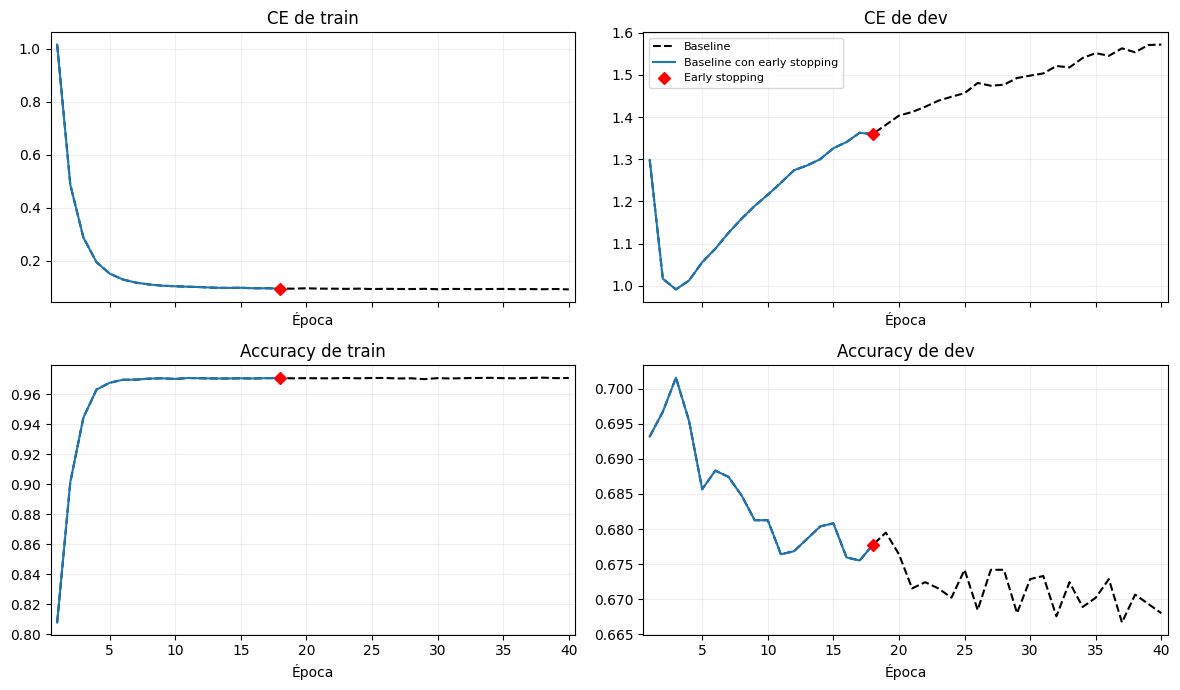

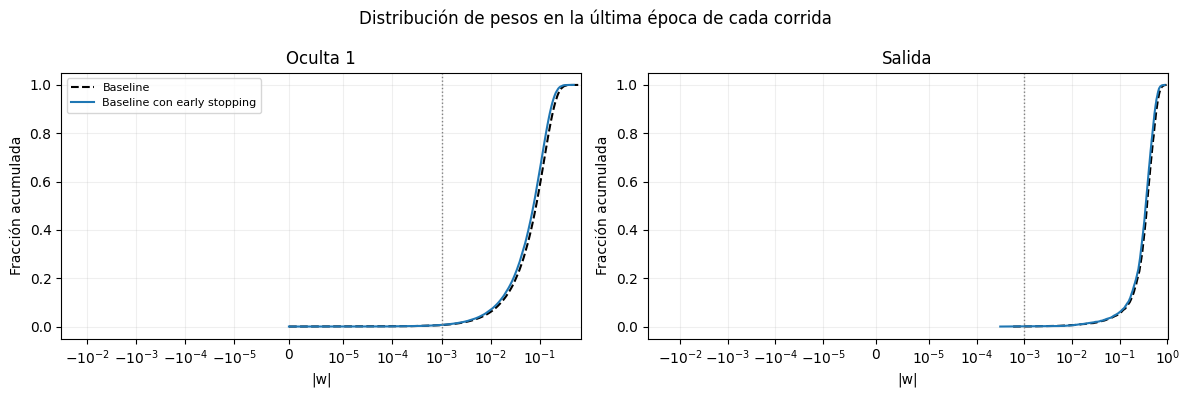

,modelo,λ₁,λ₂,dropout,BatchNorm,momento,época,épocas hechas,early stopping,accuracy train (%),accuracy dev (%),CE train,CE dev,brecha (pp),s acumulados por época,s del entrenador
0,Baseline,0,0,0.0,False,Mejor dev,3,40,False,94.43217,70.15915,0.28809,0.99152,24.27302,2.00710,17.82239
1,Baseline,0,0,0.0,False,Última,40,40,False,97.07247,66.79929,0.09280,1.57199,30.27318,16.86220,17.82239
2,Baseline con early stopping,0,0,0.0,False,Mejor dev,3,18,True,94.43217,70.15915,0.28809,0.99152,24.27302,1.31958,7.54327
3,Baseline con early stopping,0,0,0.0,False,Última,18,18,True,97.06142,67.77188,0.09600,1.35991,29.28954,7.16157,7.54327


,modelo,capa,época,media |w|,máx. |w|,"% con |w| < 0,001"
0,Baseline,Oculta 1,40,0.09573,0.66740,0.61008
1,Baseline,Salida,40,0.37844,0.96649,0.01953
2,Baseline con early stopping,Oculta 1,18,0.08418,0.49159,0.68344
3,Baseline con early stopping,Salida,18,0.35294,0.88183,0.05859


,modelo,CE por batch · épocas 1–5,CE por batch · últimas 5 épocas
0,Baseline,0.16728,0.04698
1,Baseline con early stopping,0.16728,0.04726


In [41]:
# Corre el baseline con early stopping y lo compara con el de 40 épocas.
my_early_run_dir, my_early_runs = my_regularization_sweep(
    "my_early_stopping", {"baseline": my_reg_settings(patience=15)}
)
my_compare_regularization({"Baseline con early stopping": my_early_runs["baseline"]}, my_early_run_dir)

Con semilla 3 y paciencia de 15 épocas, el modelo cortó en la época 18.
Para ese momento, la accuracy en train había subido a 97,06 % y la de dev
había bajado a 67,77 %. Al cortar recuperamos los pesos de la época 3,
con 70,16 % en dev, igual que el mejor punto del baseline. Se ahorraron
22 épocas y el tiempo medido bajó de 17,82 a 7,54 segundos.

En una corrida anterior con semilla 3 probé `patience=5`. Cortó diez épocas
antes y recuperó el mismo resultado en dev.

| Paciencia | Época de corte | Accuracy de dev al cortar | Mejor época | Mejor accuracy de dev | Tiempo del entrenador |
| ---: | ---: | ---: | ---: | ---: | ---: |
| 5 (corrida anterior) | 8 | 68,48 % | 3 | 70,16 % | 3,78 s |

### 7.7 L1 + L2 + Dropout + BatchNorm con early stopping

Partimos de los pesos iniciales del baseline. Usamos los coeficientes de la
mejor variante de 7.3 y el Dropout de la mejor variante de 7.4, según dev.
Agregamos BatchNorm y mantenemos una paciencia de 15 épocas.

Corremos también la combinación con el presupuesto completo, para medir
cuántas épocas ahorramos y si después del corte dev encontraba un mejor
punto. Comparamos ambas con el baseline, L1+L2, Dropout y BatchNorm.

In [42]:
# Corre la misma combinación con y sin early stopping.

def my_dev_accuracy(result):
    return result["history"]["best_value"]


my_l1_l2_best = max(my_l1_l2_runs.values(), key=my_dev_accuracy)
my_dropout_best = max(my_dropout_runs.values(), key=my_dev_accuracy)
my_all_settings = my_reg_settings(
    l1=my_l1_l2_best["config"]["lambda_l1"],
    l2=my_l1_l2_best["config"]["lambda_l2"],
    dropout=my_dropout_best["config"]["dropout"],
    batchnorm=True,
)
my_all_run_dir, my_all_runs = my_regularization_sweep(
    "my_all_regularization", {"combinada": my_all_settings}
)

my_all_early_run_dir, my_all_early_runs = my_regularization_sweep(
    "my_all_early_stopping",
    {"combinada": {**my_all_settings, "patience": EARLY_STOPPING_PATIENCE}},
)

[my_all_regularization_combinada] 1/40 | train loss=0.4877 acc=0.9048 | dev loss=1.0940 acc=0.6848 | lr=0.0025 | entrenamiento=0.42s
[my_all_regularization_combinada] 2/40 | train loss=0.1940 acc=0.9599 | dev loss=1.0669 acc=0.6901 | lr=0.0025 | entrenamiento=0.41s
[my_all_regularization_combinada] 3/40 | train loss=0.1268 acc=0.9676 | dev loss=1.1464 acc=0.6799 | lr=0.0025 | entrenamiento=0.39s
[my_all_regularization_combinada] 4/40 | train loss=0.1081 acc=0.9698 | dev loss=1.2119 acc=0.6786 | lr=0.0025 | entrenamiento=0.40s
[my_all_regularization_combinada] 5/40 | train loss=0.1010 acc=0.9705 | dev loss=1.2961 acc=0.6715 | lr=0.0025 | entrenamiento=0.39s
[my_all_regularization_combinada] 6/40 | train loss=0.0978 acc=0.9706 | dev loss=1.3466 acc=0.6667 | lr=0.0025 | entrenamiento=0.41s
[my_all_regularization_combinada] 7/40 | train loss=0.0969 acc=0.9704 | dev loss=1.3995 acc=0.6649 | lr=0.0025 | entrenamiento=0.39s
[my_all_regularization_combinada] 8/40 | train loss=0.0978 acc=0.9706

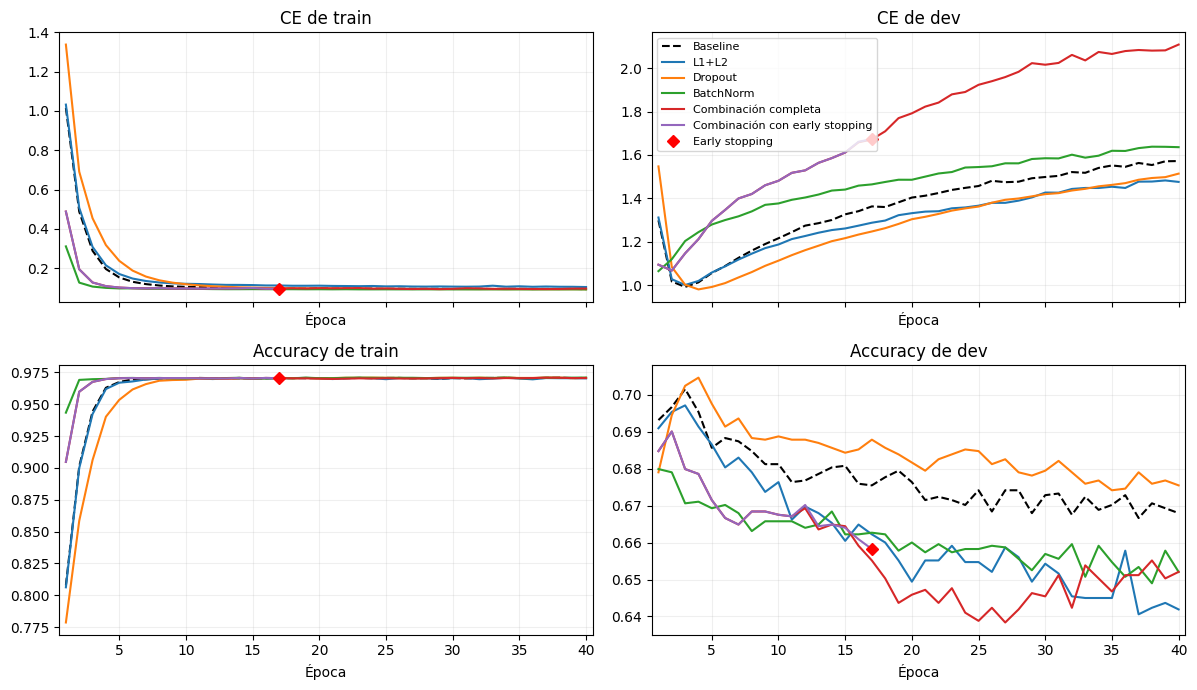

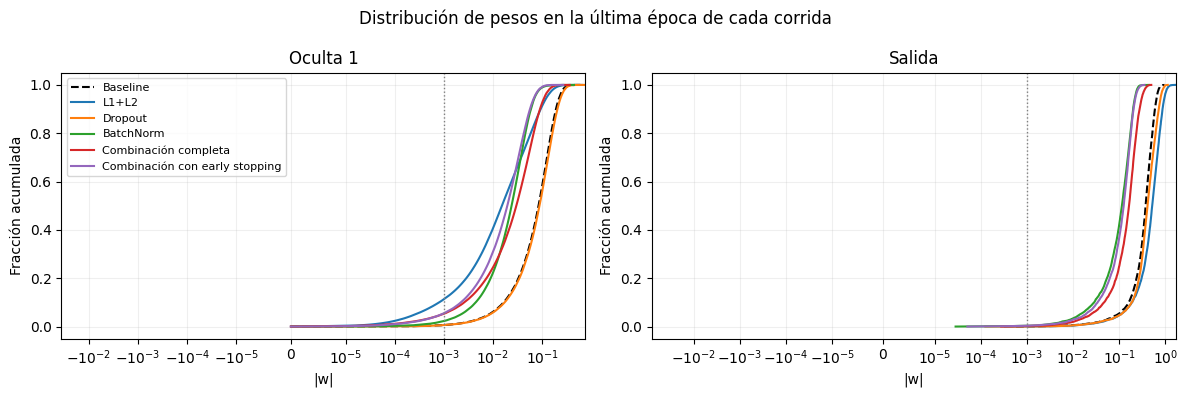

,modelo,λ₁,λ₂,dropout,BatchNorm,momento,época,épocas hechas,early stopping,accuracy train (%),accuracy dev (%),CE train,CE dev,brecha (pp),s acumulados por época,s del entrenador
0,Baseline,0,0,0.0,False,Mejor dev,3,40,False,94.43217,70.15915,0.28809,0.99152,24.27302,2.00710,17.82239
1,Baseline,0,0,0.0,False,Última,40,40,False,97.07247,66.79929,0.09280,1.57199,30.27318,16.86220,17.82239
2,L1+L2,1e-06,1e-05,0.0,False,Mejor dev,3,40,False,94.23332,69.71706,0.30794,1.00032,24.51625,1.52868,22.04082
3,L1+L2,1e-06,1e-05,0.0,False,Última,40,40,False,97.03933,64.19098,0.10359,1.47577,32.84835,21.11523,22.04082
4,Dropout,0,0,0.5,False,Mejor dev,4,40,False,94.02342,70.46861,0.31708,0.98008,23.55481,1.93356,24.72299
5,Dropout,0,0,0.5,False,Última,40,40,False,97.08352,67.55084,0.09218,1.51394,29.53268,23.60805,24.72299
6,BatchNorm,0,0,0.0,True,Mejor dev,1,40,False,94.34379,67.99293,0.31051,1.06432,26.35086,0.91384,31.64141
7,BatchNorm,0,0,0.0,True,Última,40,40,False,97.09456,65.20778,0.09152,1.63598,31.88678,30.19969,31.64141
8,Combinación completa,1e-06,1e-05,0.5,True,Mejor dev,2,40,False,95.98984,69.00973,0.19395,1.06693,26.98011,1.13126,21.35530
9,Combinación completa,1e-06,1e-05,0.5,True,Última,40,40,False,97.06142,65.20778,0.09572,2.10906,31.85364,20.47209,21.35530


,modelo,capa,época,media |w|,máx. |w|,"% con |w| < 0,001"
0,Baseline,Oculta 1,40,0.09573,0.66740,0.61008
1,Baseline,Salida,40,0.37844,0.96649,0.01953
2,L1+L2,Oculta 1,40,0.03331,0.65199,11.28883
3,L1+L2,Salida,40,0.53160,1.62317,0.03906
4,Dropout,Oculta 1,40,0.10157,0.72277,0.58844
5,Dropout,Salida,40,0.43527,1.13320,0.03906
6,BatchNorm,Oculta 1,40,0.02869,0.44311,2.26234
7,BatchNorm,Salida,40,0.11606,0.44075,0.35156
8,Combinación completa,Oculta 1,40,0.03943,0.36334,5.28633
9,Combinación completa,Salida,40,0.16397,0.49671,0.19531


,modelo,CE por batch · épocas 1–5,CE por batch · últimas 5 épocas
0,Baseline,0.16728,0.04698
1,L1+L2,0.16614,0.04820
2,Dropout,0.16192,0.04653
3,BatchNorm,0.13022,0.04588
4,Combinación completa,0.15881,0.05191
5,Combinación con early stopping,0.15881,0.05869


In [43]:
# Compara las curvas y marca dónde se detuvo la combinación.
my_compare_regularization({
    "L1+L2": my_l1_l2_best,
    "Dropout": my_dropout_best,
    "BatchNorm": my_batchnorm_runs["solo"],
    "Combinación completa": my_all_runs["combinada"],
    "Combinación con early stopping": my_all_early_runs["combinada"],
}, my_all_early_run_dir)

Con semilla 3, usé BatchNorm y Dropout en la misma capa solo para probar qué pasaba al combinar todas las técnicas. Acá Dropout va después de BatchNorm y LeakyReLU. Cambia la señal que recibe la capa siguiente durante el entrenamiento. Como también agregué L1 y L2, la comparación mide el efecto de la combinación completa. En este caso, la combinación llegó a 69,01 % en dev y terminó la época 40 con una brecha de 31,85 puntos entre train y dev.

El mejor resultado en dev de esta tabla fue con Dropout `p=0.5` solo. En la época 4 obtuvo 70,47 % de accuracy en dev, la menor pérdida de dev entre los mejores puntos de cada corrida (0,980) y la menor brecha en ese punto (23,55). Al final siguió habiendo sobreajuste, aunque terminó con 67,55 % en dev frente al 66,80 % del baseline. Para esta semilla, Dropout solo funcionó mejor que sumar todas las técnicas.

Con early stopping, la combinación cortó en la época 17 y recuperó el mismo 69,01 % de la época 2 que la corrida completa. Se ahorraron 23 épocas y el tiempo medido bajó de 21,36 a 9,16 segundos.

## 8. Búsqueda con Optuna

Cada trial usa la misma opción en todas las capas ocultas: sin
regularización, BatchNorm o Dropout. Probamos BatchNorm y Dropout por
separado porque pueden interferir.

Hacemos 24 trials con LR fijo y 24 con CLR. Cada estudio arranca con un
trial por opción y profundidad. Optuna elige la profundidad, las neuronas por capa, el
batch y el LR. Si toca Dropout, también elige `p` de 0,1 a 0,6 en pasos de 0,1.

El barrido inicial de LR usa la arquitectura del baseline. Dejamos que
todos los trials entrenen 40 épocas para darles tiempo a los que mejoran
más lento. La búsqueda usa las tres opciones de arriba y deja $\lambda_1$
y $\lambda_2$ en cero. Elegimos la mejor época por accuracy de dev.

### Ejecución desde un clon

Abrí el notebook desde la carpeta del repositorio y ejecutá las secciones
en orden. Para las secciones 8 y 9, PyTorch tiene que detectar una GPU
(`cuda` o `xpu`). La primera ejecución requiere internet para descargar
20 Newsgroups y los recursos de NLTK.

En una corrida nueva, salteá «Muestra la configuración completa del mejor
trial de cada grupo (semilla 3)» en la sección 8 y «Junta la configuración
y las métricas de test de los finalistas (semilla 3)» en la 9. Esas dos
celdas leen los archivos de la corrida original. Las demás celdas de esas
secciones muestran el resumen de Optuna y las métricas del test de la
nueva corrida.

Si tenés el ZIP de la corrida original, extraé la carpeta `ba3ca4d5af94`
dentro de `.experimentos/my_gpu_search/` en la raíz del clon para volver
a generar esas dos tablas con los resultados originales. Para consultar
los resultados de la entrega, las tablas y los gráficos ya están guardados
en este notebook.

In [95]:
# Comprueba la GPU y fija el presupuesto de búsqueda.
from pathlib import Path
import hashlib
import json
import shutil
import sqlite3
from contextlib import closing
from importlib.util import find_spec
import joblib
import pandas as pd

SEARCH_SEED = SEED
SEARCH_EPOCHS = MAX_EPOCHS
TRIALS_PER_POLICY = 24  # cambiar manualmente
CLR_HALF_EPOCHS = 2
LR_RANGE_EPOCHS = 6
LR_RANGE_LOW, LR_RANGE_HIGH = 1e-5, 1e-2
FIXED_LR_LOW = 1e-4
DEPTH_OPTIONS = [1, 2, 3]
WIDTH_OPTIONS = [128, 256, 512]
DROPOUT_RANGE = (0.1, 0.6, 0.1)
REGULARIZATION_OPTIONS = [0, "batchnorm", "dropout"]

search_device = device
if search_device.type not in ("cuda", "xpu"):
    raise RuntimeError("Seleccioná el kernel local mlp-gpu (Intel XPU) o activá GPU en Colab.")
gpu = torch.xpu if search_device.type == "xpu" else torch.cuda
search_gpu_name = gpu.get_device_name(search_device)

if find_spec("google") and find_spec("google.colab"):
    from google.colab import drive

    drive.mount("/content/drive")
    results_root = Path("/content/drive/MyDrive/TP3_RN_resultados")
    local_db_root = Path("/content/TP3_RN_db")
else:
    project = Path.cwd()
    if (project / "TP RN Regularización Bonacina").is_dir():
        project /= "TP RN Regularización Bonacina"
    results_root = project / ".experimentos" / "my_gpu_search"
    local_db_root = results_root

print(f"{search_device.type}: {search_gpu_name}")

xpu: Intel(R) Arc(TM) 140V GPU (16GB)


In [96]:
# Ajusta el TF-IDF de búsqueda con train y transforma dev.
train_clean = [preprocess_text(text) for text in train_texts_raw]
dev_clean = [preprocess_text(text) for text in dev_texts_raw]
X_search_train, X_search_dev, search_vectorizer = vectorize_data(
    train_clean, dev_clean, ngram_range=(1, 1), max_features=5000, min_df=1,
)
search_train = to_tensor_dataset(X_search_train, y_train)
search_dev = to_tensor_dataset(X_search_dev, y_dev)
del X_search_train, X_search_dev

protocol = {
    "version": 4, "seed": SEARCH_SEED, "split_id": DATA_SPLIT_ID,
    "activation": ACTIVATION, "depth_options": DEPTH_OPTIONS, "width_options": WIDTH_OPTIONS,
    "batch_sizes": BATCH_SIZES, "fixed_lr_low": FIXED_LR_LOW,
    "dropout_range": DROPOUT_RANGE,
    "baseline": {"hidden_units": BASELINE_HIDDEN_UNITS,
                 "batch_size": BASELINE_BATCH_SIZE, "lr": BASELINE_LR},
    "device_type": search_device.type,
    "epochs": SEARCH_EPOCHS, "half_cycle_epochs": CLR_HALF_EPOCHS,
    "lr_range_epochs": LR_RANGE_EPOCHS,
    "lr_range": [LR_RANGE_LOW, LR_RANGE_HIGH],
    "regularization_options": REGULARIZATION_OPTIONS,
    "train_size": len(y_train), "dev_size": len(y_dev),
    "feature_names": list(search_vectorizer.get_feature_names_out()),
}
signature = hashlib.sha256(json.dumps(protocol, sort_keys=True).encode()).hexdigest()[:12]
search_dir = results_root / signature
search_dir.mkdir(parents=True, exist_ok=True)


def save_json(path, value):
    temp = path.with_suffix(path.suffix + ".tmp")
    temp.write_text(json.dumps(value, indent=2, ensure_ascii=False), encoding="utf-8")
    temp.replace(path)


save_json(search_dir / "protocol.json", protocol)


def make_search_model(input_dim, config):
    mode = config["regularizacion"]
    set_seed(SEARCH_SEED)
    return my_MLP_model(
        input_dim, NUM_CLASSES, config["hidden_units"], config.get("activation", ACTIVATION),
        batchnorm=mode == "batchnorm",
        dropout=config["dropout"] if mode == "dropout" else 0.0,
    ).to(search_device)

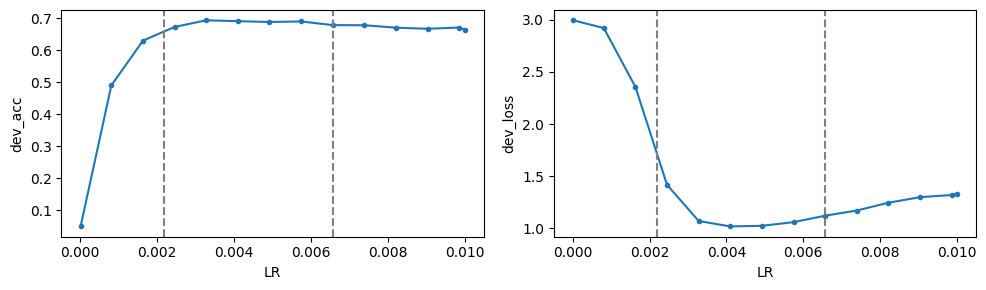

In [97]:
# Hace el LR range test con una copia nueva del baseline.
def run_lr_range_test():
    loaders = make_loaders(search_train, search_dev, batch_size=BASELINE_BATCH_SIZE, seed=SEARCH_SEED)
    train_loader, _, dev_loader = loaders
    model = make_search_model(search_train.tensors[0].shape[1], {
        "hidden_units": BASELINE_HIDDEN_UNITS, "regularizacion": 0,
    })
    optimizer = create_optimizer(model, "Adam", lr=LR_RANGE_LOW)
    total_steps = LR_RANGE_EPOCHS * len(train_loader)
    probe_every = max(1, len(train_loader) // 2)
    probes = []
    step = 0
    for _ in range(LR_RANGE_EPOCHS):
        for xb, yb in train_loader:
            model.train()
            lr = LR_RANGE_LOW + (LR_RANGE_HIGH - LR_RANGE_LOW) * step / (total_steps - 1)
            optimizer.param_groups[0]["lr"] = lr
            optimizer.zero_grad(set_to_none=True)
            loss = classification_cost(model(xb.to(search_device)), yb.to(search_device))
            if not torch.isfinite(loss):
                return probes
            loss.backward()
            optimizer.step()
            step += 1
            if step == 1 or step % probe_every == 0 or step == total_steps:
                dev_loss, dev_acc = evaluate_model(model, dev_loader)
                if not np.isfinite(dev_loss):
                    return probes
                probes.append({"step": step, "lr": lr, "dev_acc": dev_acc, "dev_loss": dev_loss})
    return probes


def lr_bounds(probes):
    if len(probes) < 3:
        raise RuntimeError("El LR range test necesita más puntos válidos.")
    peak = max(range(len(probes)), key=lambda i: probes[i]["dev_acc"])
    first = next(p for p in probes[:peak + 1] if p["dev_acc"] >= probes[peak]["dev_acc"] - 0.02)
    upper = next(
        (p for p in probes[peak + 1:] if p["dev_acc"] <= probes[peak]["dev_acc"] - 0.015),
        probes[-1],
    )
    return {"base_lr": min(first["lr"], upper["lr"] / 3), "max_lr": upper["lr"]}


range_path = search_dir / "lr_range.json"
if range_path.is_file():
    range_result = json.loads(range_path.read_text(encoding="utf-8"))
else:
    range_probes = run_lr_range_test()
    range_result = {"probes": range_probes, **lr_bounds(range_probes)}
    save_json(range_path, range_result)

range_table = pd.DataFrame(range_result["probes"])
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, metric in zip(axes, ("dev_acc", "dev_loss")):
    ax.plot(range_table["lr"], range_table[metric], marker=".")
    ax.axvline(range_result["base_lr"], color="gray", linestyle="--")
    ax.axvline(range_result["max_lr"], color="gray", linestyle="--")
    ax.set(xlabel="LR", ylabel=metric)
fig.tight_layout()
plt.show()

In [98]:
# Define el espacio de búsqueda y configura Adam con LR fijo o triangular2.
def suggest_search_config(trial, policy):
    mode = trial.suggest_categorical("regularizacion", REGULARIZATION_OPTIONS)
    depth = trial.suggest_int("n_hidden_layers", DEPTH_OPTIONS[0], DEPTH_OPTIONS[-1])
    hidden_units = [
        trial.suggest_categorical(f"units_layer_{i}", WIDTH_OPTIONS)
        for i in range(1, depth + 1)
    ]
    batch_size = trial.suggest_categorical("batch_size", BATCH_SIZES)
    low, high = range_result["base_lr"], range_result["max_lr"]
    config = {
        "regularizacion": mode, "batch_size": batch_size,
        "hidden_units": hidden_units, "activation": ACTIVATION,
        "policy": policy, "base_lr": low, "half_cycle_epochs": CLR_HALF_EPOCHS,
        "dropout": 0.0,
    }
    if policy == "clr":
        config["lr"] = trial.suggest_float("max_lr", low * 1.5, high, log=True)
        config["base_lr"] = trial.suggest_float("base_lr", min(LR_RANGE_LOW, low), low, log=True)
    else:
        config["lr"] = trial.suggest_float(
            "lr", min(FIXED_LR_LOW, low, BASELINE_LR), max(high, BASELINE_LR), log=True,
        )
    if mode == "dropout":
        dropout_min, dropout_max, dropout_step = DROPOUT_RANGE
        config["dropout"] = trial.suggest_float("dropout", dropout_min, dropout_max, step=dropout_step)
    return config


def fit_search_model(config, epochs, epoch_callback=None, batch_callback=None):
    loaders = make_loaders(
        search_train, search_dev, batch_size=config["batch_size"],
        seed=SEARCH_SEED, batchnorm=config["regularizacion"] == "batchnorm",
    )
    model = make_search_model(search_train.tensors[0].shape[1], config)
    optimizer = create_optimizer(model, "Adam", lr=config["lr"], betas=(0.9, 0.999))
    scheduler = None
    if config["policy"] == "clr":
        scheduler = optim.lr_scheduler.CyclicLR(
            optimizer, base_lr=config["base_lr"], max_lr=config["lr"],
            step_size_up=config["half_cycle_epochs"] * len(loaders[0]),
            mode="triangular2", cycle_momentum=False,
        )
    history = train_mlp_model(
        model, *loaders, optimizer, epochs=epochs, scheduler=scheduler,
        patience=None, monitor="val_acc", verbose=False,
        epoch_callback=epoch_callback, batch_callback=batch_callback,
    )
    return model, history

In [99]:
# Guarda la trayectoria de cada trial.
def search_objective(trial, policy):
    config = suggest_search_config(trial, policy)
    trial.set_user_attr("config", config)
    folder = search_dir / policy
    folder.mkdir(exist_ok=True)
    partial_history = {}
    lr_trace = []

    def capture_epoch(model, history):
        partial_history.update(history)

    def capture_batch(epoch, batch, values):
        lr_trace.append(values["lr"])

    try:
        _, history = fit_search_model(
            config, SEARCH_EPOCHS,
            epoch_callback=capture_epoch, batch_callback=capture_batch,
        )
    except FloatingPointError:
        trial.set_user_attr("diverged", True)
        save_json(folder / f"trial_{trial.number:03}.json", {
            "config": config, "history": partial_history, "lr_by_batch": lr_trace,
            "status": "diverged",
        })
        raise

    trial.set_user_attr("best_epoch", history["best_epoch"])
    save_json(folder / f"trial_{trial.number:03}.json", {
        "config": config, "history": history, "lr_by_batch": lr_trace, "status": "complete",
    })
    return history["best_value"]

In [100]:
# Ejecuta o retoma los dos estudios y guarda una copia de SQLite por trial.
def run_search(policy):
    local_dir = local_db_root / signature if local_db_root != results_root else search_dir
    local_dir.mkdir(parents=True, exist_ok=True)
    backup = search_dir / f"{policy}.sqlite3"
    database = local_dir / backup.name
    if backup != database and backup.is_file() and not database.is_file():
        shutil.copy2(backup, database)

    def save_study(study, trial):
        if database != backup:
            # SQLite trabaja en el disco local; Drive recibe una copia cerrada.
            temp_local = database.with_suffix(".snapshot")
            with closing(sqlite3.connect(database)) as origin, closing(sqlite3.connect(temp_local)) as snapshot:
                origin.backup(snapshot)
            temp_backup = backup.with_suffix(".tmp")
            shutil.copy2(temp_local, temp_backup)
            temp_backup.replace(backup)
        print(f"{policy} | trial {trial.number} | {trial.state.name} | dev={trial.value}")

    db_url = database.resolve().as_posix().replace("{", "{{").replace("}", "}}")
    study = optuna.create_study(
        study_name=policy, storage=f"sqlite:///{db_url}", load_if_exists=True,
        direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEARCH_SEED),
        pruner=optuna.pruners.NopPruner(),
    )
    if not study.trials:
        for depth in DEPTH_OPTIONS:
            for mode in REGULARIZATION_OPTIONS:
                plan = {"regularizacion": mode, "n_hidden_layers": depth}
                if depth == len(BASELINE_HIDDEN_UNITS) and mode == 0:
                    plan["batch_size"] = BASELINE_BATCH_SIZE
                    plan.update({f"units_layer_{i}": units for i, units in enumerate(BASELINE_HIDDEN_UNITS, 1)})
                    if policy == "fixed":
                        plan["lr"] = BASELINE_LR
                study.enqueue_trial(plan)

    finished = sum(
        t.state == optuna.trial.TrialState.COMPLETE
        or (t.state == optuna.trial.TrialState.FAIL and t.user_attrs.get("diverged", False))
        for t in study.trials
    )
    study.optimize(
        lambda trial: search_objective(trial, policy),
        n_trials=max(0, TRIALS_PER_POLICY - finished), callbacks=[save_study],
        catch=(FloatingPointError,),
    )
    study.trials_dataframe().to_csv(search_dir / f"trials_{policy}.csv", index=False)
    return study


search_studies = {policy: run_search(policy) for policy in ("fixed", "clr")}

best_by_policy = {policy: study.best_trial for policy, study in search_studies.items()}
baseline_trial = search_studies["fixed"].trials[0]
assert baseline_trial.state == optuna.trial.TrialState.COMPLETE

# El test se abre después de elegir las corridas con dev.
final_plan = {}
labels_by_trial = {}
dev_rows = []


def add_final_trial(label, policy, trial):
    key = (policy, trial.number)
    if key in labels_by_trial:
        final_plan[labels_by_trial[key]]["roles"].append(label)
    else:
        labels_by_trial[key] = label
        final_plan[label] = {"trial": trial.number, **trial.user_attrs, "roles": [label]}


add_final_trial("baseline", "fixed", baseline_trial)
add_final_trial("mejor_lr_fijo", "fixed", best_by_policy["fixed"])
add_final_trial("mejor_clr", "clr", best_by_policy["clr"])

regularized_candidates = []
for policy, study in search_studies.items():
    for mode in REGULARIZATION_OPTIONS:
        trials = [t for t in study.trials if t.params.get("regularizacion") == mode]
        completed = [t for t in trials if t.state == optuna.trial.TrialState.COMPLETE]
        if not completed:
            dev_rows.append({"politica": policy, "regularizacion": mode, "completos": 0, "trials": len(trials)})
            continue
        best = max(completed, key=lambda t: t.value)
        config = best.user_attrs["config"]
        dev_rows.append({
            "politica": policy, "regularizacion": mode, "completos": len(completed), "trials": len(trials),
            "trial": best.number, "capas": config["hidden_units"], "batch_size": config["batch_size"],
            "dropout": config["dropout"], "accuracy_dev": best.value,
        })
        if mode != 0:
            regularized_candidates.append((policy, best))

if regularized_candidates:
    policy, best = max(regularized_candidates, key=lambda entry: entry[1].value)
    add_final_trial("mejor_regularizado", policy, best)

save_json(search_dir / "final_plan.json", final_plan)
dev_summary = pd.DataFrame(dev_rows)
dev_summary.to_csv(search_dir / "dev_summary.csv", index=False)
display(dev_summary.round(5))

[I 2026-11-22 20:18:30,742] A new study created in RDB with name: fixed
[I 2026-11-22 20:18:50,203] Trial 0 finished with value: 0.7015915119363395 and parameters: {'regularizacion': 0, 'n_hidden_layers': 1, 'units_layer_1': 256, 'batch_size': 128, 'lr': 0.0024524713668806378}. Best is trial 0 with value: 0.7015915119363395.


fixed | trial 0 | COMPLETE | dev=0.7015915119363395


[I 2026-11-22 20:19:05,238] Trial 1 finished with value: 0.6781609195402298 and parameters: {'regularizacion': 'batchnorm', 'n_hidden_layers': 1, 'units_layer_1': 256, 'batch_size': 256, 'lr': 0.00016913912438855591}. Best is trial 0 with value: 0.7015915119363395.


fixed | trial 1 | COMPLETE | dev=0.6781609195402298


[I 2026-11-22 20:19:21,920] Trial 2 finished with value: 0.7046861184792219 and parameters: {'regularizacion': 'dropout', 'n_hidden_layers': 1, 'units_layer_1': 512, 'batch_size': 256, 'lr': 0.00032072633190850385, 'dropout': 0.5}. Best is trial 2 with value: 0.7046861184792219.


fixed | trial 2 | COMPLETE | dev=0.7046861184792219


... (87 outputs left out)

clr | trial 22 | COMPLETE | dev=0.6989389920424404


[I 2026-11-22 20:41:39,796] Trial 23 finished with value: 0.6989389920424404 and parameters: {'regularizacion': 0, 'n_hidden_layers': 1, 'units_layer_1': 512, 'batch_size': 128, 'max_lr': 0.003908067387190189, 'base_lr': 0.00012831442668740753}. Best is trial 18 with value: 0.7033598585322723.


clr | trial 23 | COMPLETE | dev=0.6989389920424404


,politica,regularizacion,completos,trials,trial,capas,batch_size,dropout,accuracy_dev
0,fixed,0,8,8,13,[512],256,0.0,0.70469
1,fixed,batchnorm,4,4,1,[256],256,0.0,0.67816
2,fixed,dropout,12,12,2,[512],256,0.5,0.70469
3,clr,0,11,11,19,[512],128,0.0,0.69938
4,clr,batchnorm,3,3,1,[512],64,0.0,0.66048
5,clr,dropout,10,10,18,[256],128,0.4,0.70336


Con semilla 3, en el barrido de LR la accuracy de dev llegó a 69,41 % cerca de `0.0033`, y la pérdida fue mínima cerca de `0.0041`. Al seguir aumentando el LR, la pérdida volvió a subir. Los primeros puntos tienen poca accuracy, pero en ese momento el modelo también había visto pocos batches. A partir del barrido, Optuna probó LR fijos de `0.0001` a `0.00657` en escala
logarítmica. Para CLR buscó el LR base entre `0.00001` y `0.00219` y el pico
inicial entre `0.00328` y `0.00657`.

El trial 2 con LR fijo y Dropout empató en 70,47 % de accuracy de dev con
el trial 13 sin regularización. En ese empate, Optuna eligió el trial 2,
que se ejecutó antes.

In [108]:
# Muestra la configuración completa del mejor trial de cada grupo (semilla 3).
from pathlib import Path
import json
import pandas as pd

seed3_study_dir = Path(".experimentos/my_gpu_search/ba3ca4d5af94")
if not seed3_study_dir.is_dir():
    seed3_study_dir = Path("TP RN Regularización Bonacina") / seed3_study_dir
if not seed3_study_dir.is_dir():
    raise FileNotFoundError("Abrí el notebook desde la carpeta del TP para cargar la corrida de semilla 3.")

seed3_protocol = json.loads((seed3_study_dir / "protocol.json").read_text(encoding="utf-8"))
assert seed3_protocol["seed"] == 3


def seed3_parameters(config):
    clr = config["policy"] == "clr"
    return {
        "semilla": seed3_protocol["seed"],
        "épocas máx.": seed3_protocol["epochs"],
        "activación": config["activation"],
        "capas ocultas": len(config["hidden_units"]),
        "neuronas por capa": config["hidden_units"],
        "batch size": config["batch_size"],
        "regularización": config["regularizacion"],
        "dropout": config["dropout"] if config["regularizacion"] == "dropout" else None,
        "política LR": "CLR" if clr else "Fijo",
        "LR fijo": None if clr else config["lr"],
        "LR base": config["base_lr"] if clr else None,
        "LR pico inicial": config["lr"] if clr else None,
        "medio ciclo (épocas)": config["half_cycle_epochs"] if clr else None,
    }


seed3_dev = pd.read_csv(seed3_study_dir / "dev_summary.csv")
seed3_winners = []
for row in seed3_dev.dropna(subset=["trial"]).itertuples(index=False):
    number = int(row.trial)
    trial_path = seed3_study_dir / row.politica / f"trial_{number:03}.json"
    trial = json.loads(trial_path.read_text(encoding="utf-8"))
    seed3_winners.append({
        "trial": number, **seed3_parameters(trial["config"]),
        "mejor época dev": trial["history"]["best_epoch"],
        "accuracy dev": row.accuracy_dev,
        "trials completos": row.completos, "trials": row.trials,
    })

with pd.option_context("display.max_columns", None, "display.precision", 10):
    display(pd.DataFrame(seed3_winners))

,trial,semilla,épocas máx.,activación,capas ocultas,neuronas por capa,batch size,regularización,dropout,política LR,LR fijo,LR base,LR pico inicial,medio ciclo (épocas),mejor época dev,accuracy dev,trials completos,trials
0,13,3,40,leaky_relu,1,[512],256,0,NaN,Fijo,0.0002126253,NaN,NaN,NaN,20,0.7046861185,8,8
1,1,3,40,leaky_relu,1,[256],256,batchnorm,NaN,Fijo,0.0001691391,NaN,NaN,NaN,14,0.6781609195,4,4
2,2,3,40,leaky_relu,1,[512],256,dropout,0.5,Fijo,0.0003207263,NaN,NaN,NaN,26,0.7046861185,12,12
3,19,3,40,leaky_relu,1,[512],128,0,NaN,CLR,NaN,0.0000578717,0.0038467021,2.0,3,0.6993810787,11,11
4,1,3,40,leaky_relu,1,[512],64,batchnorm,NaN,CLR,NaN,0.0001075565,0.0034033425,2.0,1,0.6604774536,3,3
5,18,3,40,leaky_relu,1,[256],128,dropout,0.4,CLR,NaN,0.0020967211,0.0046778263,2.0,4,0.7033598585,10,10


## 9. Entrenamiento final y evaluación

Evaluamos el baseline, el mejor trial con LR fijo, el mejor con CLR y el
mejor entre BatchNorm y Dropout. Si un trial ocupa dos lugares, lo
evaluamos una vez. Por eso quedaron tres modelos en esta corrida. El mejor
trial con LR fijo también fue el mejor regularizado. Volvimos a entrenar
esas configuraciones con train y recuperamos la mejor época según dev.
Los histogramas muestran los pesos de esa época por capa.

Reportamos el test oficial completo y, aparte, la accuracy en los documentos
cuyo texto no aparece en el train oficial. Al ignorar mayúsculas y
diferencias de espacios encontramos 18 copias exactas entre los 7532
documentos del test. El orden de los tres modelos se mantiene en los 7514
restantes.

In [101]:
# Carga el plan elegido en dev y prepara los modelos finales.
plan_path = search_dir / "final_plan.json"
if not plan_path.is_file():
    raise FileNotFoundError("Primero completá la búsqueda de la sección 8.")
final_plan = json.loads(plan_path.read_text(encoding="utf-8"))
if any(row["config"].get("regularizacion") not in REGULARIZATION_OPTIONS for row in final_plan.values()):
    raise ValueError("Volvé a correr la sección 8 con las opciones actuales de regularización.")
final_dir = search_dir / "final"
final_dir.mkdir(exist_ok=True)
joblib.dump(search_vectorizer, final_dir / "vectorizer.joblib")
save_json(final_dir / "plan.json", final_plan)
final_models, final_histories = {}, {}
for label, plan in final_plan.items():
    config = plan["config"]
    folder = final_dir / label
    folder.mkdir(exist_ok=True)
    best_path = folder / "model_best.pt"
    history_path = folder / "history.json"
    batches_path = folder / "batches.csv"
    settings_path = folder / "config.json"
    settings = {
        **plan, "seed": SEARCH_SEED, "epochs": SEARCH_EPOCHS,
        "device": str(search_device), "gpu": search_gpu_name,
        "torch_version": str(torch.__version__),
    }
    if all(path.is_file() for path in (settings_path, best_path, history_path, batches_path)):
        saved = json.loads(settings_path.read_text(encoding="utf-8"))
        if saved == settings:
            model = make_search_model(search_train.tensors[0].shape[1], config)
            model.load_state_dict(torch.load(best_path, map_location="cpu", weights_only=True))
            final_models[label] = model.eval()
            final_histories[label] = json.loads(history_path.read_text(encoding="utf-8"))
            print(f"{label}: modelo guardado")
            continue

    lr_trace = []

    def record_final_batch(epoch, batch, values):
        lr_trace.append({"epoch": epoch, "batch": batch, **values})

    model, history = fit_search_model(config, SEARCH_EPOCHS, batch_callback=record_final_batch)
    torch.save({key: tensor.detach().cpu() for key, tensor in model.state_dict().items()}, best_path)
    save_json(history_path, history)
    pd.DataFrame(lr_trace).to_csv(batches_path, index=False)
    save_json(settings_path, settings)
    final_models[label], final_histories[label] = model, history
    print(f"{label}: modelo entrenado")

baseline: modelo entrenado
mejor_lr_fijo: modelo entrenado
mejor_clr: modelo entrenado


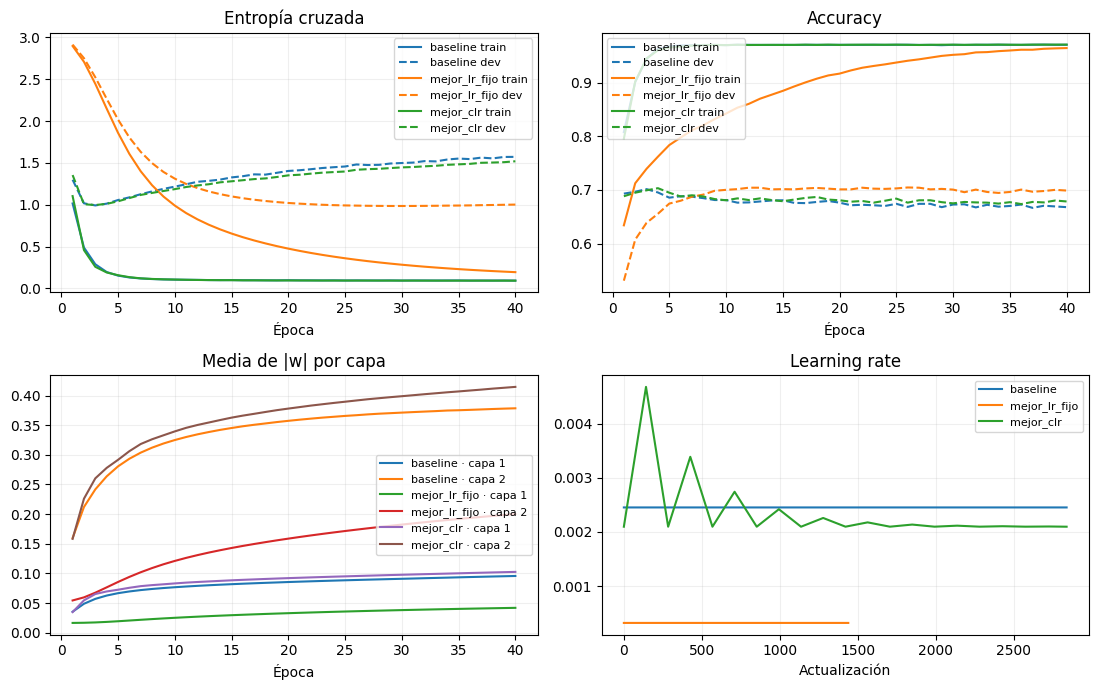

In [102]:
# Grafica pérdida, accuracy, pesos y LR de las corridas finales.
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for label in final_models:
    folder = final_dir / label
    history = final_histories[label]
    epochs = range(1, history["epochs_completed"] + 1)
    for ax, metric in zip(axes[0], ("loss", "acc")):
        train_line, = ax.plot(epochs, history[f"train_{metric}"], label=f"{label} train")
        ax.plot(epochs, history[f"val_{metric}"], color=train_line.get_color(),
                linestyle="--", label=f"{label} dev")
    for layer_index, name in enumerate(history["weights"][0], start=1):
        values = [w[name]["mean_abs"] for w in history["weights"]]
        axes[1, 0].plot(epochs, values, label=f"{label} · capa {layer_index}")
    batches = pd.read_csv(folder / "batches.csv")
    axes[1, 1].plot(np.arange(1, len(batches) + 1), batches["lr"], label=label)

for ax, title, xlabel in zip(
    axes.flat, ("Entropía cruzada", "Accuracy", "Media de |w| por capa", "Learning rate"),
    ("Época", "Época", "Época", "Actualización"),
):
    ax.set(title=title, xlabel=xlabel)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(final_dir / "training_curves.png", dpi=150)
plt.show()

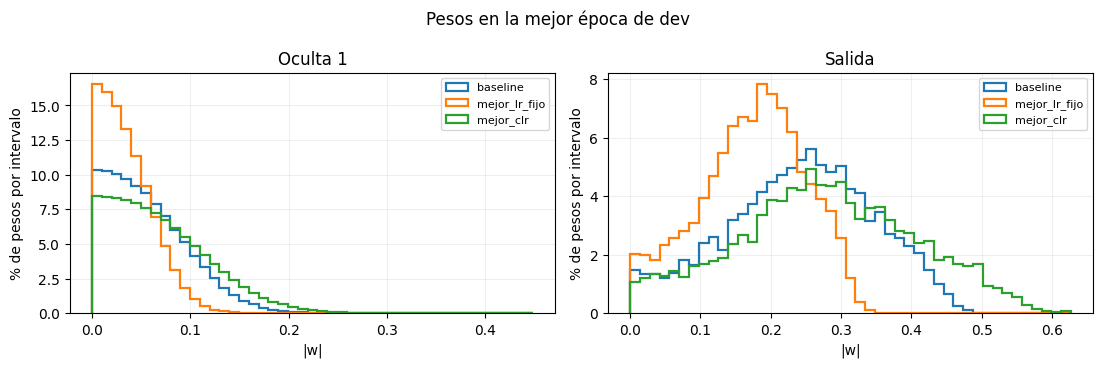

In [103]:
# Compara los histogramas de |w| de los modelos finales, capa por capa.
layer_weights = {}
for label, model in final_models.items():
    linear_layers = [layer for layer in model.modules() if isinstance(layer, nn.Linear)]
    for i, layer in enumerate(linear_layers[:-1], start=1):
        layer_weights.setdefault(f"Oculta {i}", {})[label] = layer.weight.detach().abs().cpu().numpy().ravel()
    layer_weights.setdefault("Salida", {})[label] = linear_layers[-1].weight.detach().abs().cpu().numpy().ravel()

layer_titles = [name for name in layer_weights if name != "Salida"] + ["Salida"]
colors = dict(zip(final_models, plt.get_cmap("tab10").colors))
n_rows = (len(layer_titles) + 1) // 2
fig, axes = plt.subplots(n_rows, 2, figsize=(11, 3.7 * n_rows), squeeze=False)
for ax, title in zip(axes.flat, layer_titles):
    weights_by_model = layer_weights[title]
    # Mismos intervalos por capa. Usamos porcentajes porque los modelos tienen distintos tamaños.
    xmax = max(values.max() for values in weights_by_model.values())
    bins = np.linspace(0, xmax if xmax > 0 else 1.0, 46)
    for label, values in weights_by_model.items():
        ax.hist(values, bins=bins, weights=np.full(len(values), 100.0 / len(values)),
                histtype="step", linewidth=1.6, color=colors[label], label=label)
    ax.set(title=title, xlabel="|w|", ylabel="% de pesos por intervalo")
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)

for ax in list(axes.flat)[len(layer_titles):]:
    ax.set_visible(False)
fig.suptitle("Pesos en la mejor época de dev")
fig.tight_layout()
fig.savefig(final_dir / "weight_histograms.png", dpi=150)
plt.show()

Test: 7532 documentos | Copias del train oficial: 18


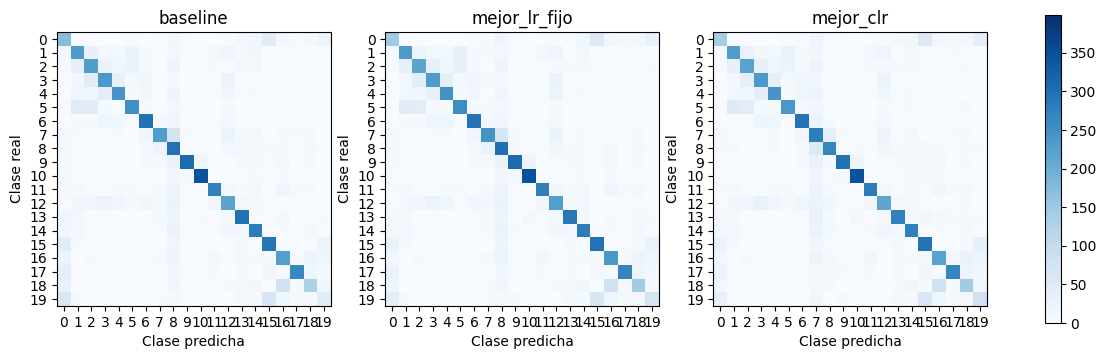

,modelo,roles,regularizacion,dropout,capas,politica_lr,trial,epoca,accuracy_dev,accuracy_test,ce_test,accuracy_test_sin_copias,n_test_sin_copias
0,baseline,baseline,0,0.0,[256],fixed,0,3,0.70159,0.64671,1.18992,0.64706,7514
1,mejor_lr_fijo,"mejor_lr_fijo, mejor_regularizado",dropout,0.5,[512],fixed,2,26,0.70469,0.65308,1.17440,0.65345,7514
2,mejor_clr,mejor_clr,dropout,0.4,[256],clr,18,4,0.70336,0.64326,1.24979,0.64360,7514


In [104]:
# Aplica el vocabulario de train al test y guarda métricas y matrices.
newsgroups_test = fetch_20newsgroups(
    subset="test", remove=("headers", "footers", "quotes"),
)
assert newsgroups_test.target_names == class_names
test_texts_raw, y_test = newsgroups_test.data, newsgroups_test.target
test_overlap = np.array([document_key(text) in known_document_keys for text in test_texts_raw])
print(f"Test: {len(y_test)} documentos | Copias del train oficial: {test_overlap.sum()}")

test_clean = [preprocess_text(text) for text in test_texts_raw]
X_final_test = search_vectorizer.transform(test_clean)
final_test_loader = DataLoader(to_tensor_dataset(X_final_test, y_test), batch_size=256)


@torch.no_grad()
def predict_test(model, loader):
    model.eval()
    loss_sum, predictions = 0.0, []
    for xb, yb in loader:
        logits = model(xb.to(search_device))
        loss_sum += classification_cost(logits, yb.to(search_device), reduction="sum").item()
        predictions.extend(logits.argmax(dim=1).cpu().tolist())
    return loss_sum / len(loader.dataset), predictions


summary = []
fig, axes = plt.subplots(1, len(final_models), figsize=(5 * len(final_models), 5), squeeze=False)
for ax, (label, model) in zip(axes.flat, final_models.items()):
    loss, predictions = predict_test(model, final_test_loader)
    accuracy = accuracy_score(y_test, predictions)
    matrix = confusion_matrix(y_test, predictions, labels=range(NUM_CLASSES))
    report = classification_report(y_test, predictions, labels=range(NUM_CLASSES),
                                   target_names=class_names, output_dict=True, zero_division=0)
    folder = final_dir / label
    save_json(folder / "classification_report.json", report)
    pd.DataFrame(matrix, index=class_names, columns=class_names).to_csv(folder / "confusion_matrix.csv")
    pd.DataFrame({
        "real": y_test, "prediccion": predictions, "repetido_train_oficial": test_overlap,
    }).to_csv(folder / "predictions.csv", index=False)
    plan = final_plan[label]
    history = final_histories[label]
    summary.append({
        "modelo": label, "roles": ", ".join(plan["roles"]),
        "regularizacion": plan["config"]["regularizacion"],
        "dropout": plan["config"]["dropout"], "capas": plan["config"]["hidden_units"],
        "politica_lr": plan["config"]["policy"], "trial": plan["trial"],
        "epoca": history["best_epoch"], "accuracy_dev": history["best_value"],
        "accuracy_test": accuracy, "ce_test": loss,
        "accuracy_test_sin_copias": np.mean((np.asarray(predictions) == y_test)[~test_overlap]),
        "n_test_sin_copias": int((~test_overlap).sum()),
    })
    image = ax.imshow(matrix, cmap="Blues", vmin=0, vmax=max(np.bincount(y_test)))
    ax.set(title=label, xlabel="Clase predicha", ylabel="Clase real",
           xticks=range(NUM_CLASSES), yticks=range(NUM_CLASSES))
fig.colorbar(image, ax=axes.ravel().tolist(), shrink=0.8)
fig.savefig(final_dir / "confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()
final_summary = pd.DataFrame(summary)
final_summary.to_csv(final_dir / "test_summary.csv", index=False)
display(final_summary.round(5))

In [109]:
# Junta la configuración y las métricas de test de los finalistas (semilla 3).
seed3_final_dir = seed3_study_dir / "final"
seed3_plan = json.loads((seed3_final_dir / "plan.json").read_text(encoding="utf-8"))
seed3_test = pd.read_csv(seed3_final_dir / "test_summary.csv")
seed3_configs = pd.DataFrame([
    {"modelo": label, "trial": row["trial"], **seed3_parameters(row["config"])}
    for label, row in seed3_plan.items()
])
seed3_final = seed3_configs.merge(
    seed3_test[["modelo", "roles", "epoca", "accuracy_dev", "accuracy_test",
                "ce_test", "accuracy_test_sin_copias"]],
    on="modelo", validate="one_to_one",
).rename(columns={"epoca": "mejor época dev"})

with pd.option_context("display.max_columns", None, "display.precision", 10):
    display(seed3_final)

,modelo,trial,semilla,épocas máx.,activación,capas ocultas,neuronas por capa,batch size,regularización,dropout,política LR,LR fijo,LR base,LR pico inicial,medio ciclo (épocas),roles,mejor época dev,accuracy_dev,accuracy_test,ce_test,accuracy_test_sin_copias
0,baseline,0,3,40,leaky_relu,1,[256],128,0,NaN,Fijo,0.0024524714,NaN,NaN,NaN,baseline,3,0.7015915119,0.6467073818,1.1899154712,0.6470588235
1,mejor_lr_fijo,2,3,40,leaky_relu,1,[512],256,dropout,0.5,Fijo,0.0003207263,NaN,NaN,NaN,"mejor_lr_fijo, mejor_regularizado",26,0.7046861185,0.6530801912,1.1743993997,0.6534468991
2,mejor_clr,18,3,40,leaky_relu,1,[256],128,dropout,0.4,CLR,NaN,0.0020967211,0.0046778263,2.0,mejor_clr,4,0.7033598585,0.6432554434,1.2497927250,0.6435986159


Con semilla 3, el mejor resultado en test fue el de una capa oculta de **512 neuronas**, batch **256**, Dropout `p=0.5` y LR fijo de `0.000321`. Llegó a **65,31 %** de accuracy, frente al **64,67 %** del baseline y al **64,33 %** del mejor CLR. En dev quedaron cerca: **70,47 %** con LR fijo y **70,34 %** con CLR. El fijo llegó a su mejor valor en la época 26. CLR llegó en la época 4 con **256 neuronas**, batch **128**, Dropout `p=0.4` y un LR que en el primer ciclo fue de `0.00210` a `0.00468`.

El baseline tenía una capa por diseño. Los dos ganadores de Optuna también
tuvieron una capa. Esa profundidad concentró 30 de los 48 trials, así que
tuvo más combinaciones probadas en esta búsqueda.

| Capas ocultas | Trials LR fijo | Trials CLR | Mejor accuracy de dev entre ambas búsquedas |
| ---: | ---: | ---: | ---: |
| 1 | 14 | 16 | 70,47 % |
| 2 | 6 | 4 | 69,89 % |
| 3 | 4 | 4 | 68,74 % |

En la época 40, el modelo con LR fijo tenía 69,89 % en dev y el de CLR
67,86 %. El LR más bajo pudo ayudar a sostener la accuracy, pero también
cambiaron las neuronas, el batch y el Dropout. Para medir el efecto del
LR por separado habría que comparar las dos políticas con el resto fijo.